In [ ]:
!nvidia-smi
!pip -q install ultralytics

Mon Nov  9 20:52:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import zipfile

archive = Path("/content/drive/MyDrive/Colab Notebooks/YOLO.zip")
destination = Path("/content/datasets")

assert archive.exists(), f"Архив не найден: {archive}"

with zipfile.ZipFile(archive) as z:
    z.extractall(destination)

print("Распаковано в:", destination)
print("Содержимое:", [p.name for p in destination.iterdir()])

Распаковано в: /content/datasets
Содержимое: ['YOLO']


In [ ]:
from pathlib import Path
import yaml

root = Path("/content/datasets/YOLO")
assert root.is_dir(), f"Не найдена папка: {root}"


classes = (root / "classes.txt").read_text(
    encoding="utf-8-sig"
).splitlines()
assert classes, "classes.txt пуст"


for folder in ["images/train", "images/val"]:
    assert (root / folder).is_dir(), f"Не найдена папка: {root / folder}"

config = {
    "path": str(root),
    "train": "images/train",
    "val": "images/val",
    "names": {i: name.strip() for i, name in enumerate(classes)},
}

if (root / "images/test").is_dir():
    config["test"] = "images/test"

data_path = root / "data.yaml"


if data_path.exists():
    backup = root / "data.original.yaml"
    if not backup.exists():
        backup.write_bytes(data_path.read_bytes())

data_path.write_text(
    yaml.safe_dump(config, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

print(data_path.read_text())

path: /content/datasets/YOLO
train: images/train
val: images/val
names:
  0: box_hitech
test: images/test



In [ ]:
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO
import torch

data_path = Path("/content/datasets/YOLO/data.yaml")

assert data_path.exists(), f"Не найден файл: {data_path}"
assert torch.cuda.is_available(), "Включите GPU в настройках Colab"
assert Path("/content/drive/MyDrive").is_dir(), "Сначала подключите Google Drive"

print("GPU:", torch.cuda.get_device_name(0))
print("Конфигурация датасета:")
print(data_path.read_text())

run_name = "boxes_" + datetime.now().strftime("%Y%m%d_%H%M%S")
project = "/content/drive/MyDrive/yolo_boxes"

model = YOLO("yolo11n.pt")

model.train(
    data=str(data_path),
    epochs=100,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project=project,
    name=run_name,
    patience=20,
    seed=42,
    plots=True,
)

run_dir = Path(model.trainer.save_dir)
best_path = run_dir / "weights/best.pt"

print("Лучшая модель:", best_path)
print("Папка результатов:", run_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
Конфигурация датасета:
path: /content/datasets/YOLO
train: images/train
val: images/val
names:
  0: box_hitech
test: images/test

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn

Лучшая модель: /content/drive/MyDrive/yolo_boxes/boxes_20261109_211959/weights/best.pt


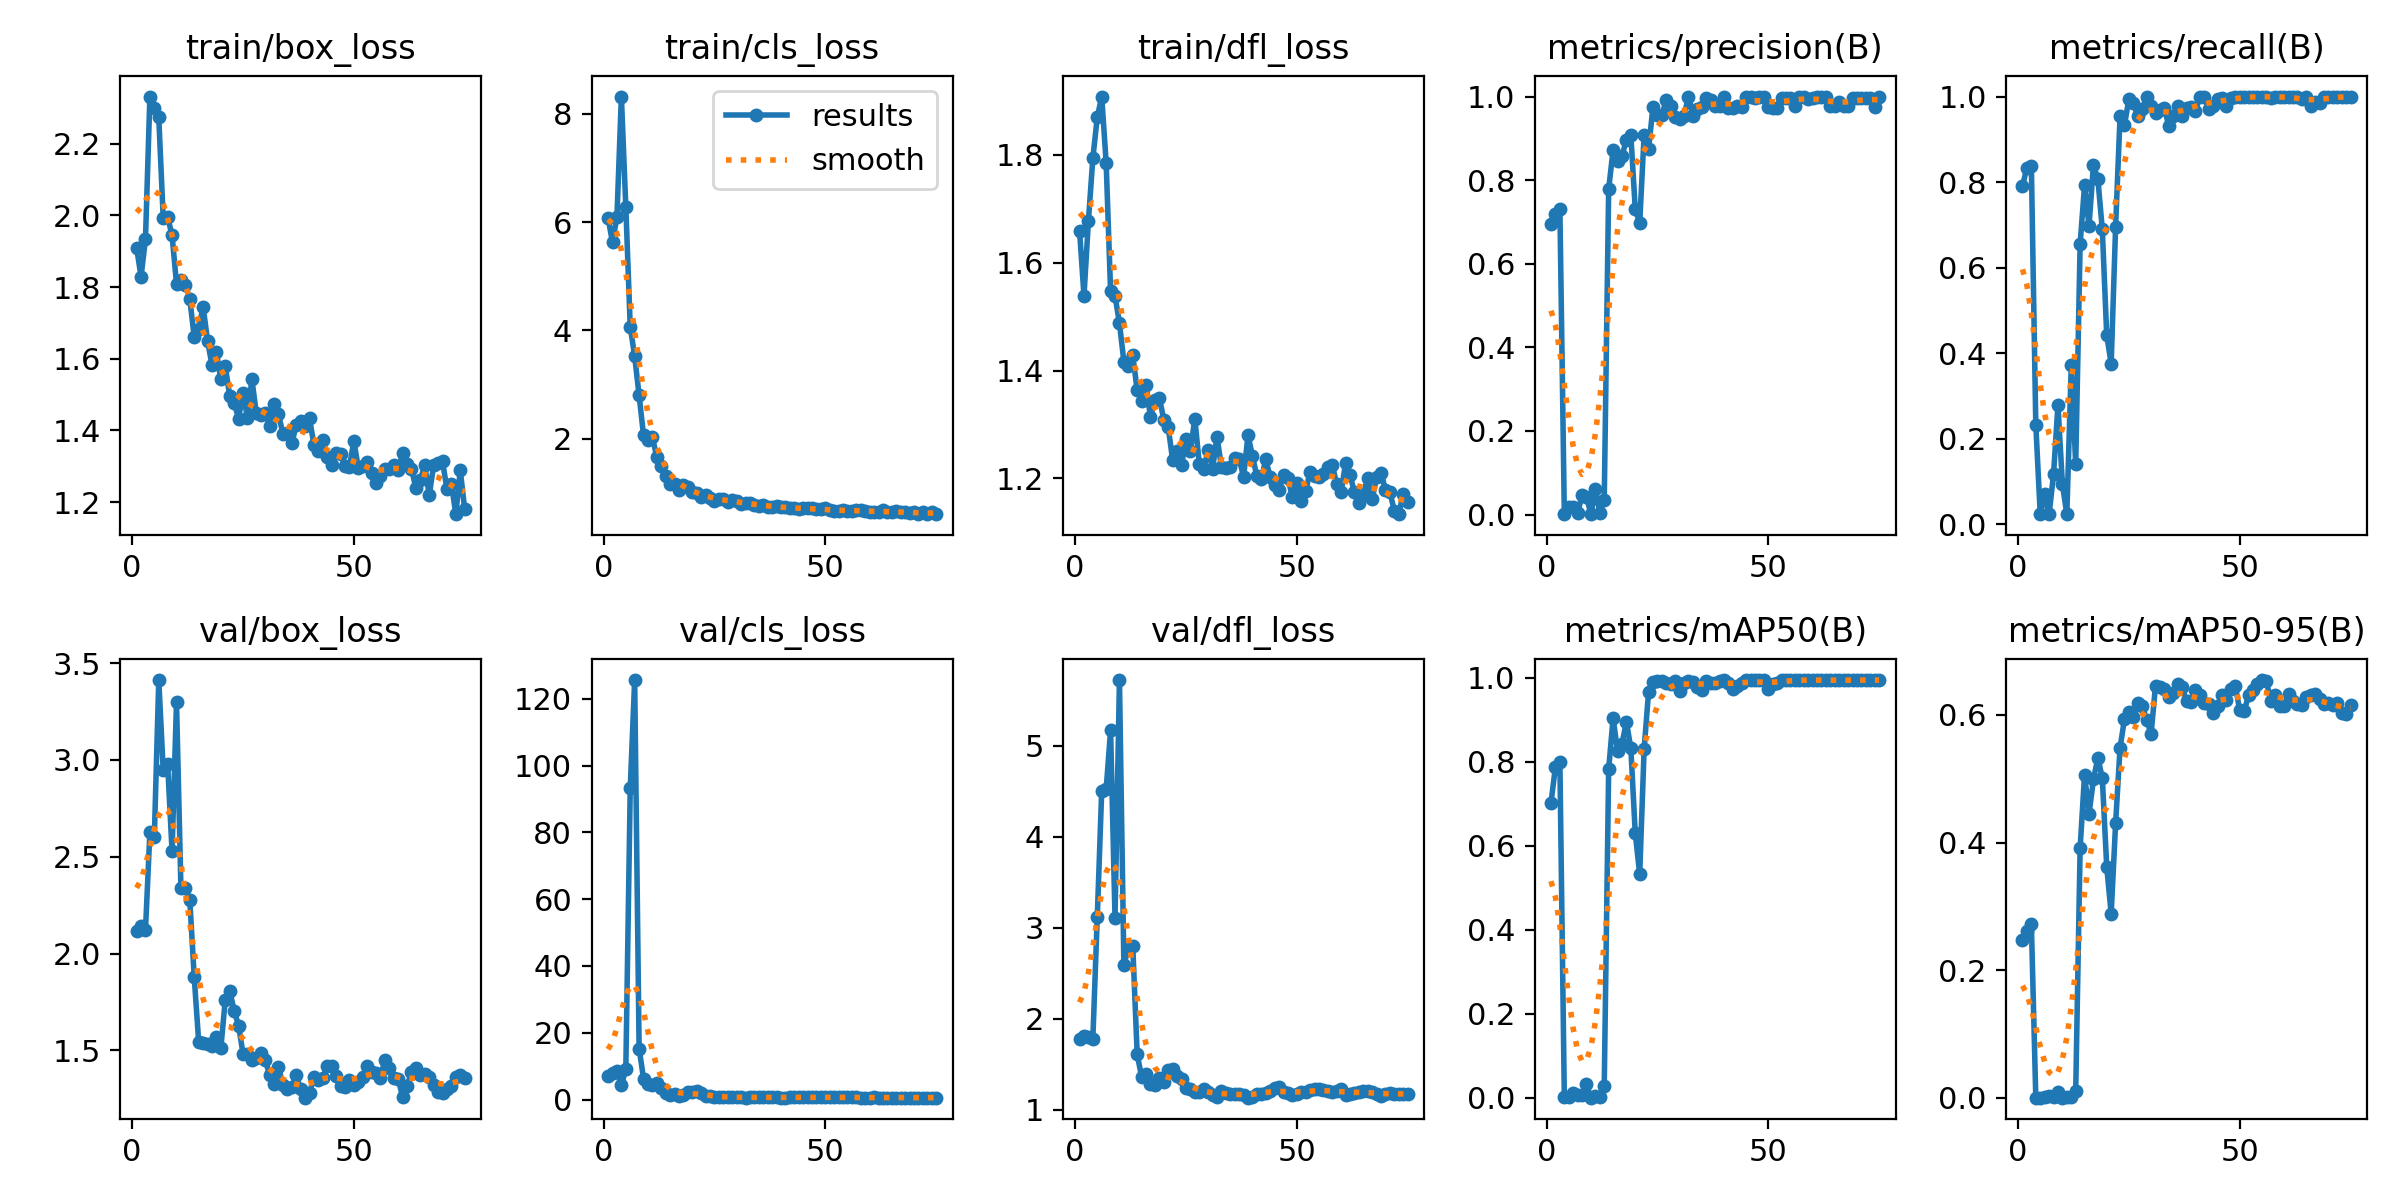

In [ ]:
from IPython.display import display, Image

print("Лучшая модель:", best_path)

# Графики обучения
display(Image(filename=str(run_dir / "results.png")))

In [ ]:
from ultralytics import YOLO

best = YOLO(str(best_path))

root = data_path.parent
images_dir = root / "images/test"

if not images_dir.is_dir() or not any(images_dir.iterdir()):
    images_dir = root / "images/val"


for result in best.predict(
    source=str(images_dir),
    conf=0.25,
    device=0,
    save=True,          # картинки с рамками
    show_labels=True,   # название класса
    show_conf=True,     # уверенность
    save_txt=True,      # координаты найденных объектов
    save_conf=True,     # уверенность в текстовых файлах
    project=str(run_dir),
    name="detections",
    exist_ok=True,
    stream=True,
):
    pass

print("Веса:", best_path)
print("Картинки:", run_dir / "detections")


image 1/16 /content/datasets/YOLO/images/test/e95b55c8-photo_20261109_101432_438751.jpg: 480x640 2 box_hitechs, 10.9ms
image 2/16 /content/datasets/YOLO/images/test/ea70e0a3-photo_20261109_101302_403104.jpg: 480x640 4 box_hitechs, 32.0ms
image 3/16 /content/datasets/YOLO/images/test/ed25f4f7-photo_20261109_101431_427633.jpg: 480x640 3 box_hitechs, 23.9ms
image 4/16 /content/datasets/YOLO/images/test/ee7a0332-photo_20261109_101441_450470.jpg: 480x640 3 box_hitechs, 26.3ms
image 5/16 /content/datasets/YOLO/images/test/f042de37-photo_20261109_101333_428495.jpg: 480x640 2 box_hitechs, 18.6ms
image 6/16 /content/datasets/YOLO/images/test/f1296c5d-photo_20261109_101356_423258.jpg: 480x640 1 box_hitech, 27.9ms
image 7/16 /content/datasets/YOLO/images/test/f3aea2b1-photo_20261109_101443_449234.jpg: 480x640 4 box_hitechs, 13.3ms
image 8/16 /content/datasets/YOLO/images/test/f4ec7e30-photo_20261109_101309_435836.jpg: 480x640 1 box_hitech, 13.7ms
image 9/16 /content/datasets/YOLO/images/test/f7d

In [ ]:
from pathlib import Path
from importlib.metadata import version
from google.colab import files
import shutil


weights = Path(best_path)
assert weights.is_file(), f"Не найдены веса: {weights}"

package = Path("/content/box_detector")
package.mkdir(exist_ok=True)

shutil.copy2(weights, package / "best.pt")

(package / "requirements.txt").write_text(
    f"ultralytics=={version('ultralytics')}\n",
    encoding="utf-8",
)

script = '''
import argparse
import json
from pathlib import Path

from ultralytics import YOLO


def main():
    parser = argparse.ArgumentParser(
        description="Поиск коробок на изображении"
    )
    parser.add_argument("image", help="Путь к изображению")
    parser.add_argument("--conf", type=float, default=0.25)
    parser.add_argument("--device", default="cpu")
    parser.add_argument("--output", default="results")
    args = parser.parse_args()

    image = Path(args.image)
    if not image.is_file():
        parser.error(f"Картинка не найдена: {image}")
    if not 0 <= args.conf <= 1:
        parser.error("--conf должен быть от 0 до 1")

    weights = Path(__file__).resolve().parent / "best.pt"
    model = YOLO(str(weights))

    result = model.predict(
        source=str(image),
        conf=args.conf,
        imgsz=640,
        device=args.device,
        verbose=False,
    )[0]

    detections = []
    for box in result.boxes:
        class_id = int(box.cls.item())
        detections.append({
            "class_id": class_id,
            "class_name": result.names[class_id],
            "confidence": round(float(box.conf.item()), 4),
            "xyxy": [round(v, 1) for v in box.xyxy[0].tolist()],
        })

    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)

    annotated = output / f"{image.stem}_detected.jpg"
    report_path = output / f"{image.stem}_result.json"

    result.save(filename=str(annotated))

    report = {
        "image": str(image),
        "found": bool(detections),
        "count": len(detections),
        "threshold": args.conf,
        "detections": detections,
        "annotated_image": str(annotated),
    }

    report_path.write_text(
        json.dumps(report, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    print("КОРОБКА НАЙДЕНА" if report["found"]
          else "КОРОБКА НЕ ОБНАРУЖЕНА")
    print(json.dumps(report, ensure_ascii=False, indent=2))


if __name__ == "__main__":
    main()
'''

(package / "detect.py").write_text(script.lstrip(), encoding="utf-8")

archive = shutil.make_archive(
    "/content/box_detector",
    "zip",
    root_dir="/content",
    base_dir="box_detector",
)

files.download(archive)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import zipfile

archive = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "extra_training_dataset_drones.zip"
)
destination = Path("/content/datasets/extra")

assert archive.is_file(), f"Не найден архив: {archive}"

with zipfile.ZipFile(archive) as z:
    z.extractall(destination)


candidates = [
    p.parent for p in destination.rglob("classes.txt")
    if (p.parent / "images").is_dir()
]

assert len(candidates) == 1, (
    f"Не удалось однозначно найти датасет: {candidates}"
)

new_root = candidates[0]
old_root = Path("/content/datasets/YOLO")

print("Новый датасет:", new_root)
print("В images:", [p.name for p in (new_root / "images").iterdir()][:15])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Новый датасет: /content/datasets/extra/extra_training_dataset_drones
В images: ['9b2e3350-IMG_3290.jpg', 'be46d1a5-IMG_20261109_164105563.jpg', '400c1723-IMG_3167.jpg', 'd18bbfaa-IMG_3270.jpg', '5691efce-IMG_3168.jpg', 'bca302fd-IMG_3153.jpg', 'def6ee96-IMG_3293.jpg', 'ff12b146-IMG_3286.jpg', 'fec7ca42-IMG_3288.jpg', '276eb63d-IMG_3305.jpg', '7f2fc908-IMG_3289.jpg', '76119304-IMG_3138.jpg', 'a39b274d-IMG_20261109_164107175.jpg', '1f8bb5f5-IMG_20261109_164053157.jpg', 'eabcecf4-IMG_3311.jpg']


In [ ]:
import yaml

def read_classes(root):
    return (root / "classes.txt").read_text(
        encoding="utf-8-sig"
    ).splitlines()

assert read_classes(old_root) == read_classes(new_root), (
    "Названия или порядок классов различаются! "
    "Нужно согласовать номера классов в разметке."
)

classes = read_classes(old_root)
assert classes and all(name.strip() for name in classes), (
    "Проверьте classes.txt: пустой файл или пустые строки"
)

for root in [old_root, new_root]:
    for split in ["train", "val", "test"]:
        for kind in ["images", "labels"]:
            folder = root / kind / split
            assert folder.is_dir(), (
                f"Нет папки {folder}. "
                "Сначала разделите изображения и разметку."
            )

config = {
    "train": [
        str(old_root / "images/train"),
        str(new_root / "images/train"),
    ],
    "val": [
        str(old_root / "images/val"),
        str(new_root / "images/val"),
    ],
    "test": [
        str(old_root / "images/test"),
        str(new_root / "images/test"),
    ],
    "names": {i: name.strip() for i, name in enumerate(classes)},
}

combined_yaml = Path("/content/datasets/combined.yaml")
combined_yaml.write_text(
    yaml.safe_dump(config, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

print(combined_yaml.read_text())

FileNotFoundError: [Errno 2] No such file or directory: '/content/datasets/YOLO/classes.txt'

In [ ]:
from pathlib import Path

print("Найденные датасеты в Colab:")

for classes_file in Path("/content/datasets").rglob("classes.txt"):
    root = classes_file.parent
    print(f"\nПапка: {root}")
    print("Классы:", repr(classes_file.read_text(encoding="utf-8-sig")))

    for kind in ["images", "labels"]:
        for split in ["train", "val", "test"]:
            folder = root / kind / split
            count = (
                sum(p.is_file() for p in folder.iterdir())
                if folder.is_dir() else None
            )
            print(
                f"  {kind}/{split}:",
                f"{count} файлов" if count is not None else "НЕТ ПАПКИ"
            )

print("\nТекущие переменные:")
print("old_root:", globals().get("old_root", "не задан"))
print("new_root:", globals().get("new_root", "не задан"))

Найденные датасеты в Colab:

Папка: /content/datasets/extra/extra_training_dataset_drones
Классы: 'box_hitech\n'
  images/train: 120 файлов
  images/val: 25 файлов
  images/test: 27 файлов
  labels/train: 120 файлов
  labels/val: 25 файлов
  labels/test: 27 файлов

Текущие переменные:
old_root: /content/datasets/YOLO
new_root: /content/datasets/extra/extra_training_dataset_drones


In [ ]:
from pathlib import Path
import yaml

new_root = Path(
    "/content/datasets/extra/extra_training_dataset_drones"
)

config = {
    "path": str(new_root),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "box hitech"},
}

new_yaml = new_root / "data_finetune.yaml"
new_yaml.write_text(
    yaml.safe_dump(config, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

print(new_yaml.read_text())

path: /content/datasets/extra/extra_training_dataset_drones
train: images/train
val: images/val
test: images/test
names:
  0: box hitech



In [ ]:
for path in Path("/content/drive/MyDrive/yolo_boxes").rglob("best.pt"):
    print(path)

/content/drive/MyDrive/yolo_boxes/boxes_20261109_211959/weights/best.pt


In [ ]:
old_weights = Path(
    "/content/drive/MyDrive/yolo_boxes/boxes_20261109_211959/weights/best.pt"
)

assert old_weights.is_file(), f"Не найдены веса: {old_weights}"

In [ ]:
%pip install -q ultralytics

In [ ]:
from pathlib import Path
import zipfile

archive = Path(
    "/content/drive/MyDrive/Colab Notebooks/YOLO.zip"
)
destination = Path("/content/datasets/old_restored")

assert archive.is_file(), (
    f"Не найден архив: {archive}. Проверьте подключение Google Drive."
)

with zipfile.ZipFile(archive) as z:
    z.extractall(destination)

image_folders = [
    p for p in destination.rglob("images")
    if p.is_dir()
]
assert len(image_folders) == 1, (
    f"Найденные папки images: {image_folders}"
)

old_root = image_folders[0].parent
print("Старый датасет:", old_root)

for kind in ["images", "labels"]:
    for split in ["train", "val", "test"]:
        folder = old_root / kind / split
        print(
            f"{kind}/{split}:",
            f"{sum(p.is_file() for p in folder.iterdir())} файлов"
            if folder.is_dir() else "НЕТ ПАПКИ"
        )

print("\nclasses.txt:",
      "есть" if (old_root / "classes.txt").is_file() else "НЕТ")

print("\nСодержимое images:")
print([p.name for p in (old_root / "images").iterdir()][:10])

Старый датасет: /content/datasets/old_restored/YOLO
images/train: 78 файлов
images/val: 17 файлов
images/test: 16 файлов
labels/train: 78 файлов
labels/val: 17 файлов
labels/test: 16 файлов

classes.txt: есть

Содержимое images:
['val', 'train', 'test']


In [ ]:
from pathlib import Path
import yaml

base = Path("/content/datasets")


new_root = base / "extra/extra_training_dataset_drones"
assert (new_root / "classes.txt").is_file(), (
    "Новый датасет не найден — распакуйте второй архив заново"
)


old_candidates = [
    p.parent
    for p in base.rglob("classes.txt")
    if new_root not in p.parents
    and (p.parent / "images/train").is_dir()
    and (p.parent / "images/val").is_dir()
]

assert len(old_candidates) == 1, (
    f"Найдено старых датасетов: {old_candidates}. "
    "Если список пуст — распакуйте YOLO.zip заново."
)

old_root = old_candidates[0]

def classes(root):
    return [
        name.strip()
        for name in (root / "classes.txt").read_text(
            encoding="utf-8-sig"
        ).splitlines()
    ]

print("Старый датасет:", old_root, classes(old_root))
print("Новый датасет:", new_root, classes(new_root))

assert classes(old_root) == classes(new_root), (
    "Классы различаются. Проверьте их названия и номера "
    "перед объединением датасетов."
)

for root in [old_root, new_root]:
    for split in ["train", "val"]:
        for kind in ["images", "labels"]:
            folder = root / kind / split
            assert folder.is_dir(), f"Не найдена папка: {folder}"

config = {
    "train": [
        str(old_root / "images/train"),
        str(new_root / "images/train"),
    ],
    "val": [
        str(old_root / "images/val"),
        str(new_root / "images/val"),
    ],
    "names": dict(enumerate(classes(old_root))),
}

combined_yaml = base / "combined.yaml"
combined_yaml.write_text(
    yaml.safe_dump(config, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

print("\nСоздан:", combined_yaml)
print(combined_yaml.read_text())

Старый датасет: /content/datasets/old_restored/YOLO ['box_hitech']
Новый датасет: /content/datasets/extra/extra_training_dataset_drones ['box_hitech']

Создан: /content/datasets/combined.yaml
train:
- /content/datasets/old_restored/YOLO/images/train
- /content/datasets/extra/extra_training_dataset_drones/images/train
val:
- /content/datasets/old_restored/YOLO/images/val
- /content/datasets/extra/extra_training_dataset_drones/images/val
names:
  0: box_hitech



In [18]:
from ultralytics import YOLO
from datetime import datetime

model = YOLO(str(old_weights))
print("Классы исходной модели:", model.names)

assert len(model.names) == 1, "Нужно проверить соответствие классов"

model.train(
    data=str(combined_yaml),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    optimizer="AdamW",
    lr0=0.001,
    patience=15,
    seed=42,
    plots=True,
    project="/content/drive/MyDrive/yolo_boxes",
    name="finetune_" + datetime.now().strftime("%Y%m%d_%H%M%S"),
)

finetune_dir = Path(model.trainer.save_dir)
new_weights = finetune_dir / "weights/best.pt"

print("Дообученная модель:", new_weights)

Классы исходной модели: {0: 'box_hitech'}
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/combined.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/yolo_boxes/boxes_20261109_211959/weights/best.pt, mom

results.png


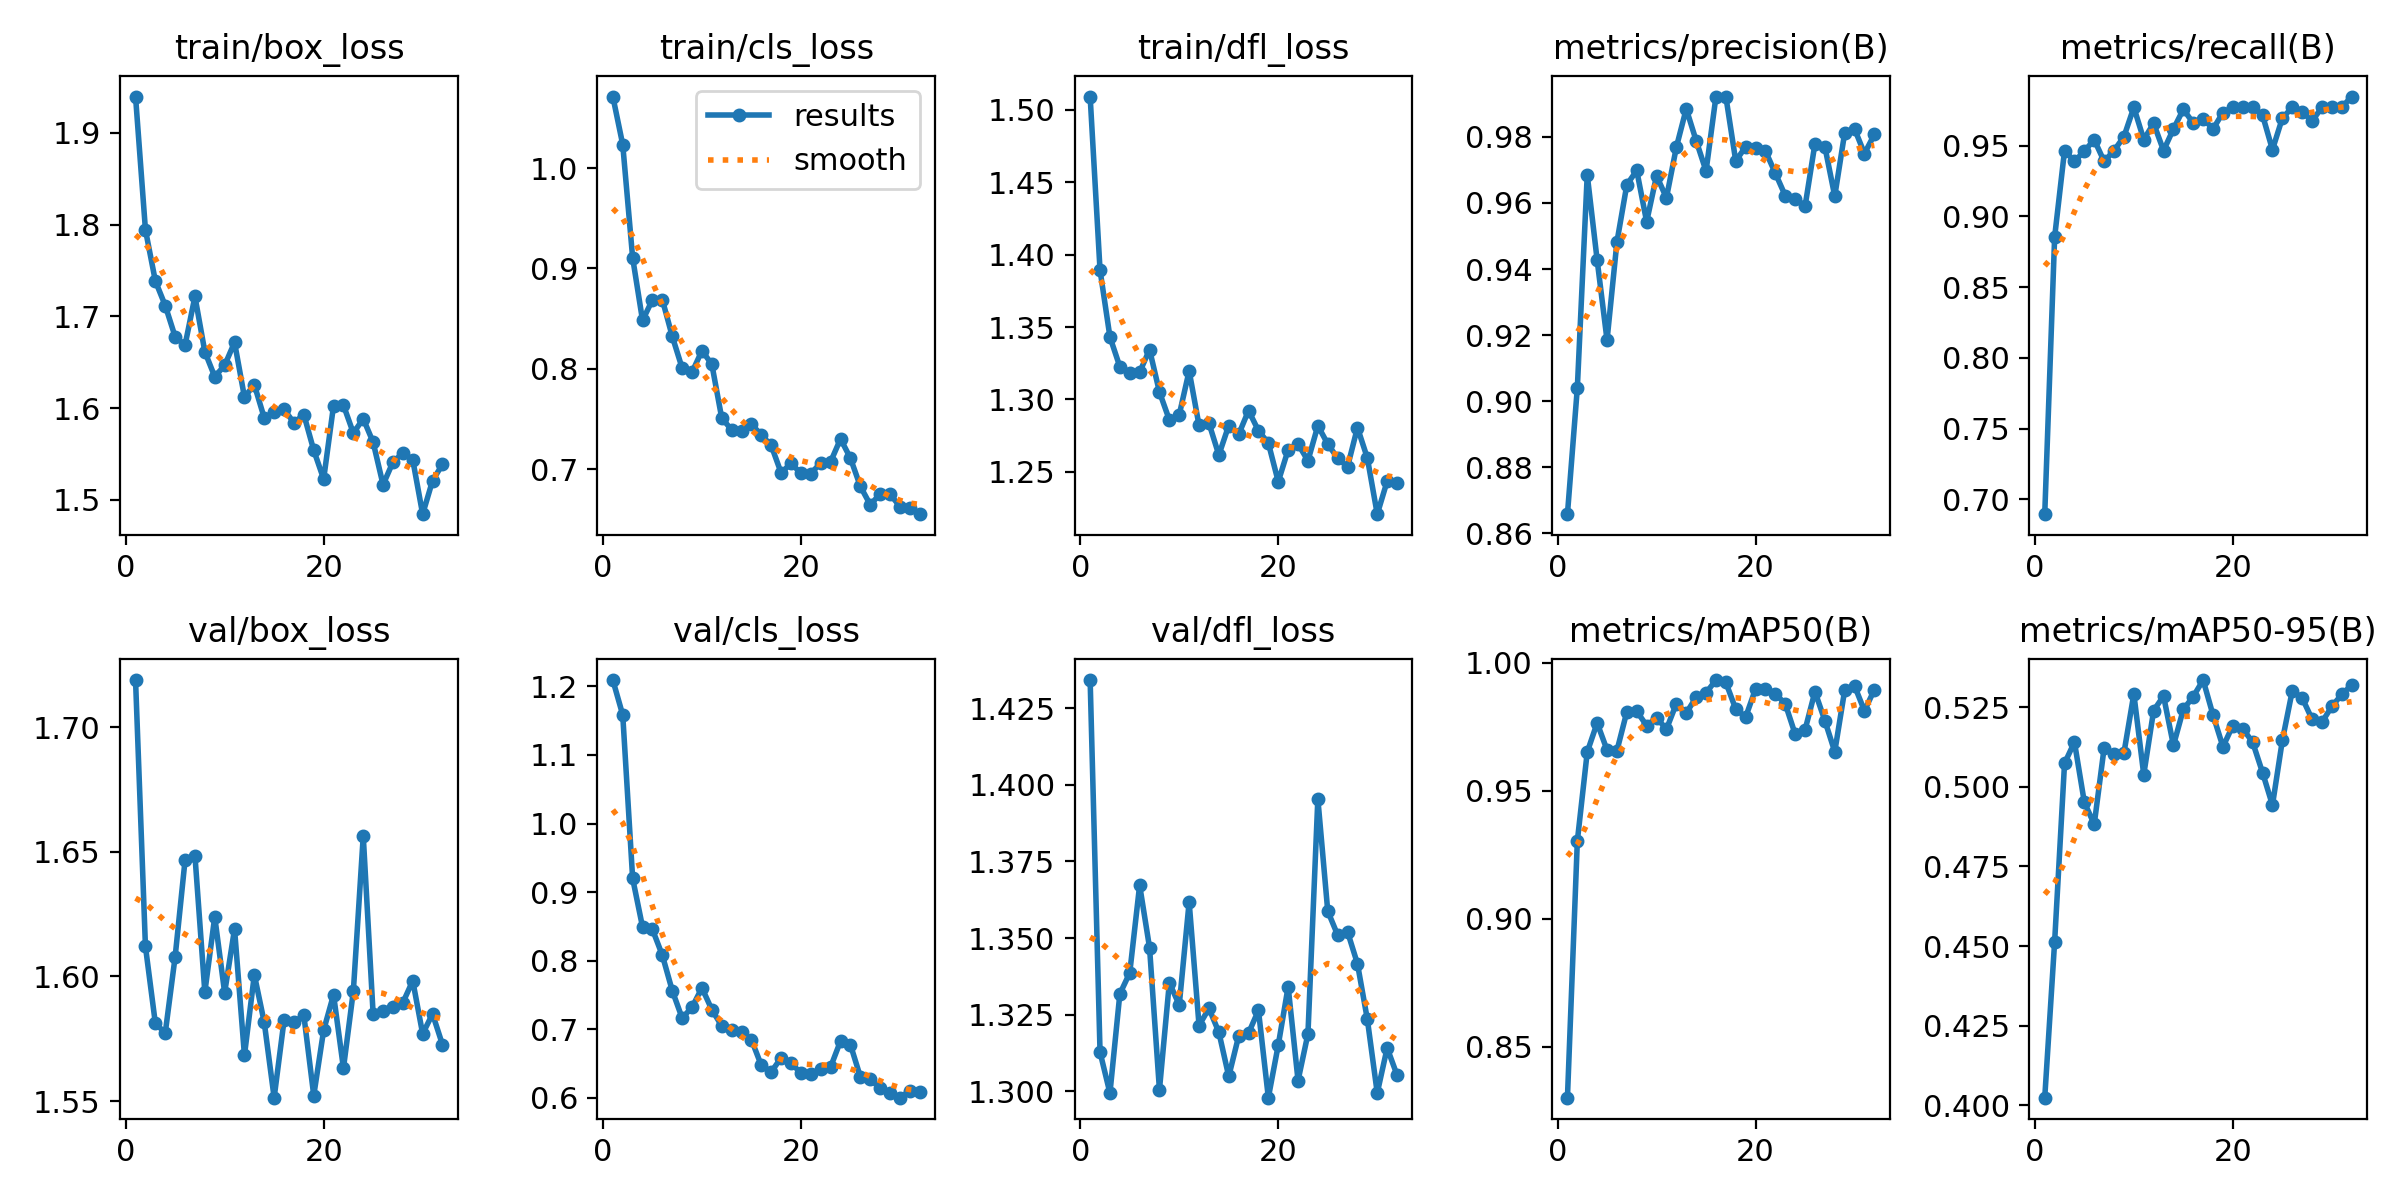

BoxPR_curve.png


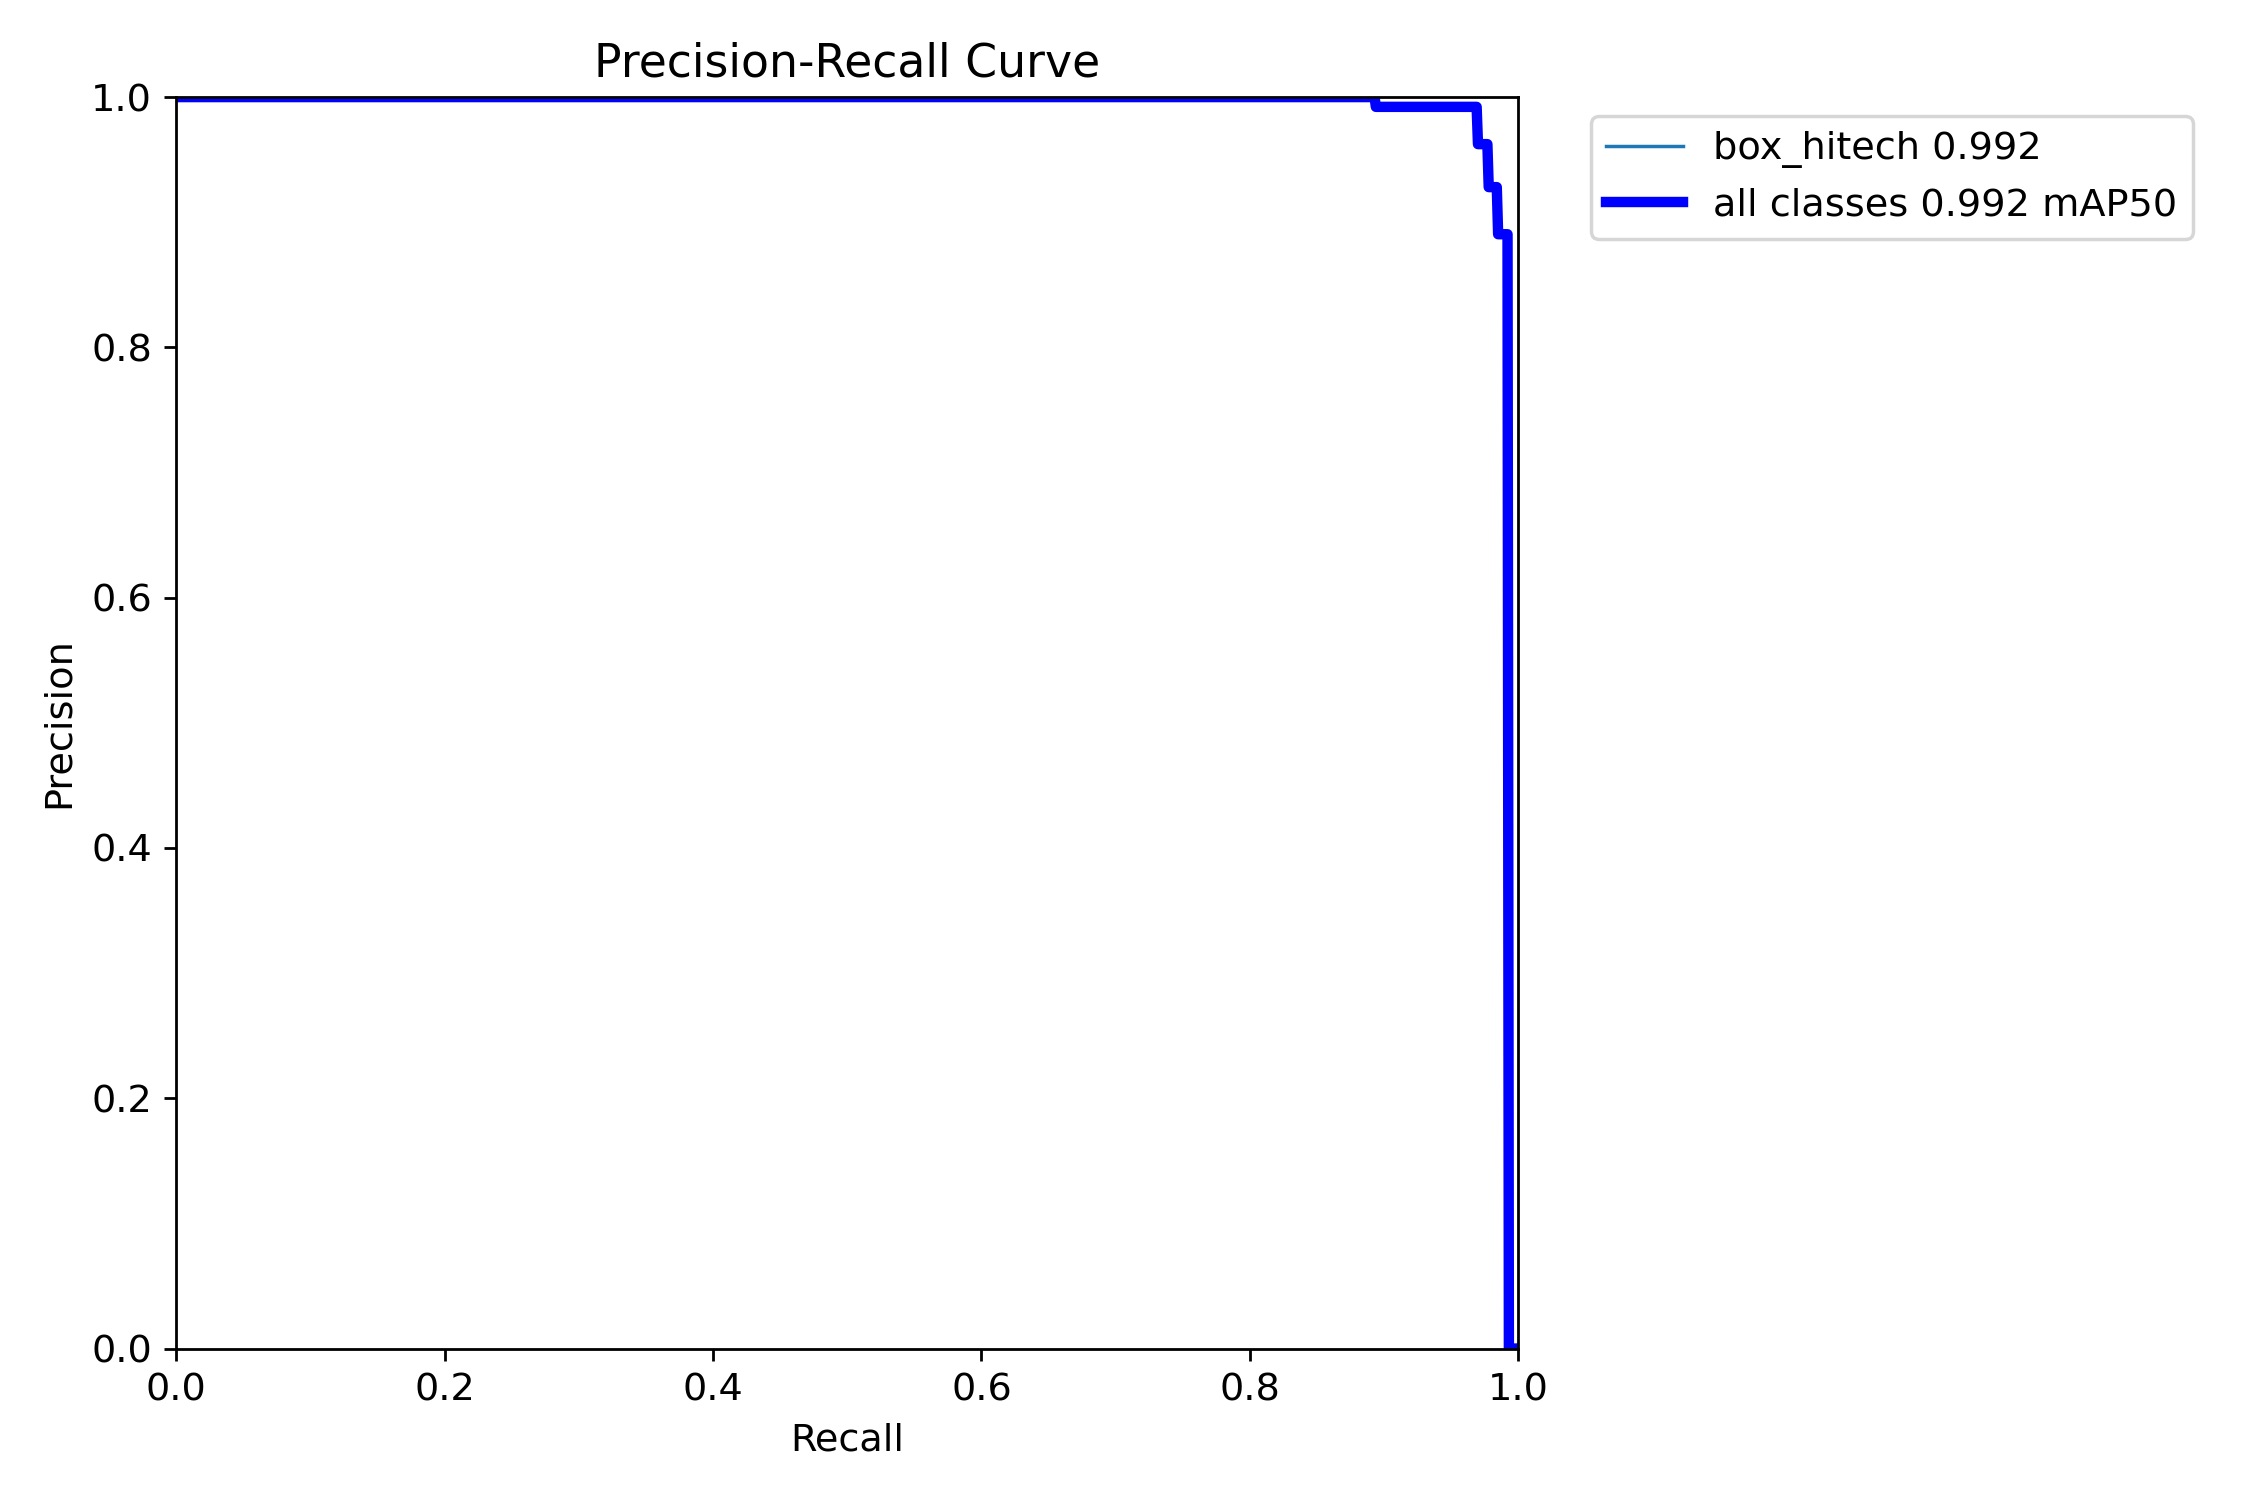

BoxF1_curve.png


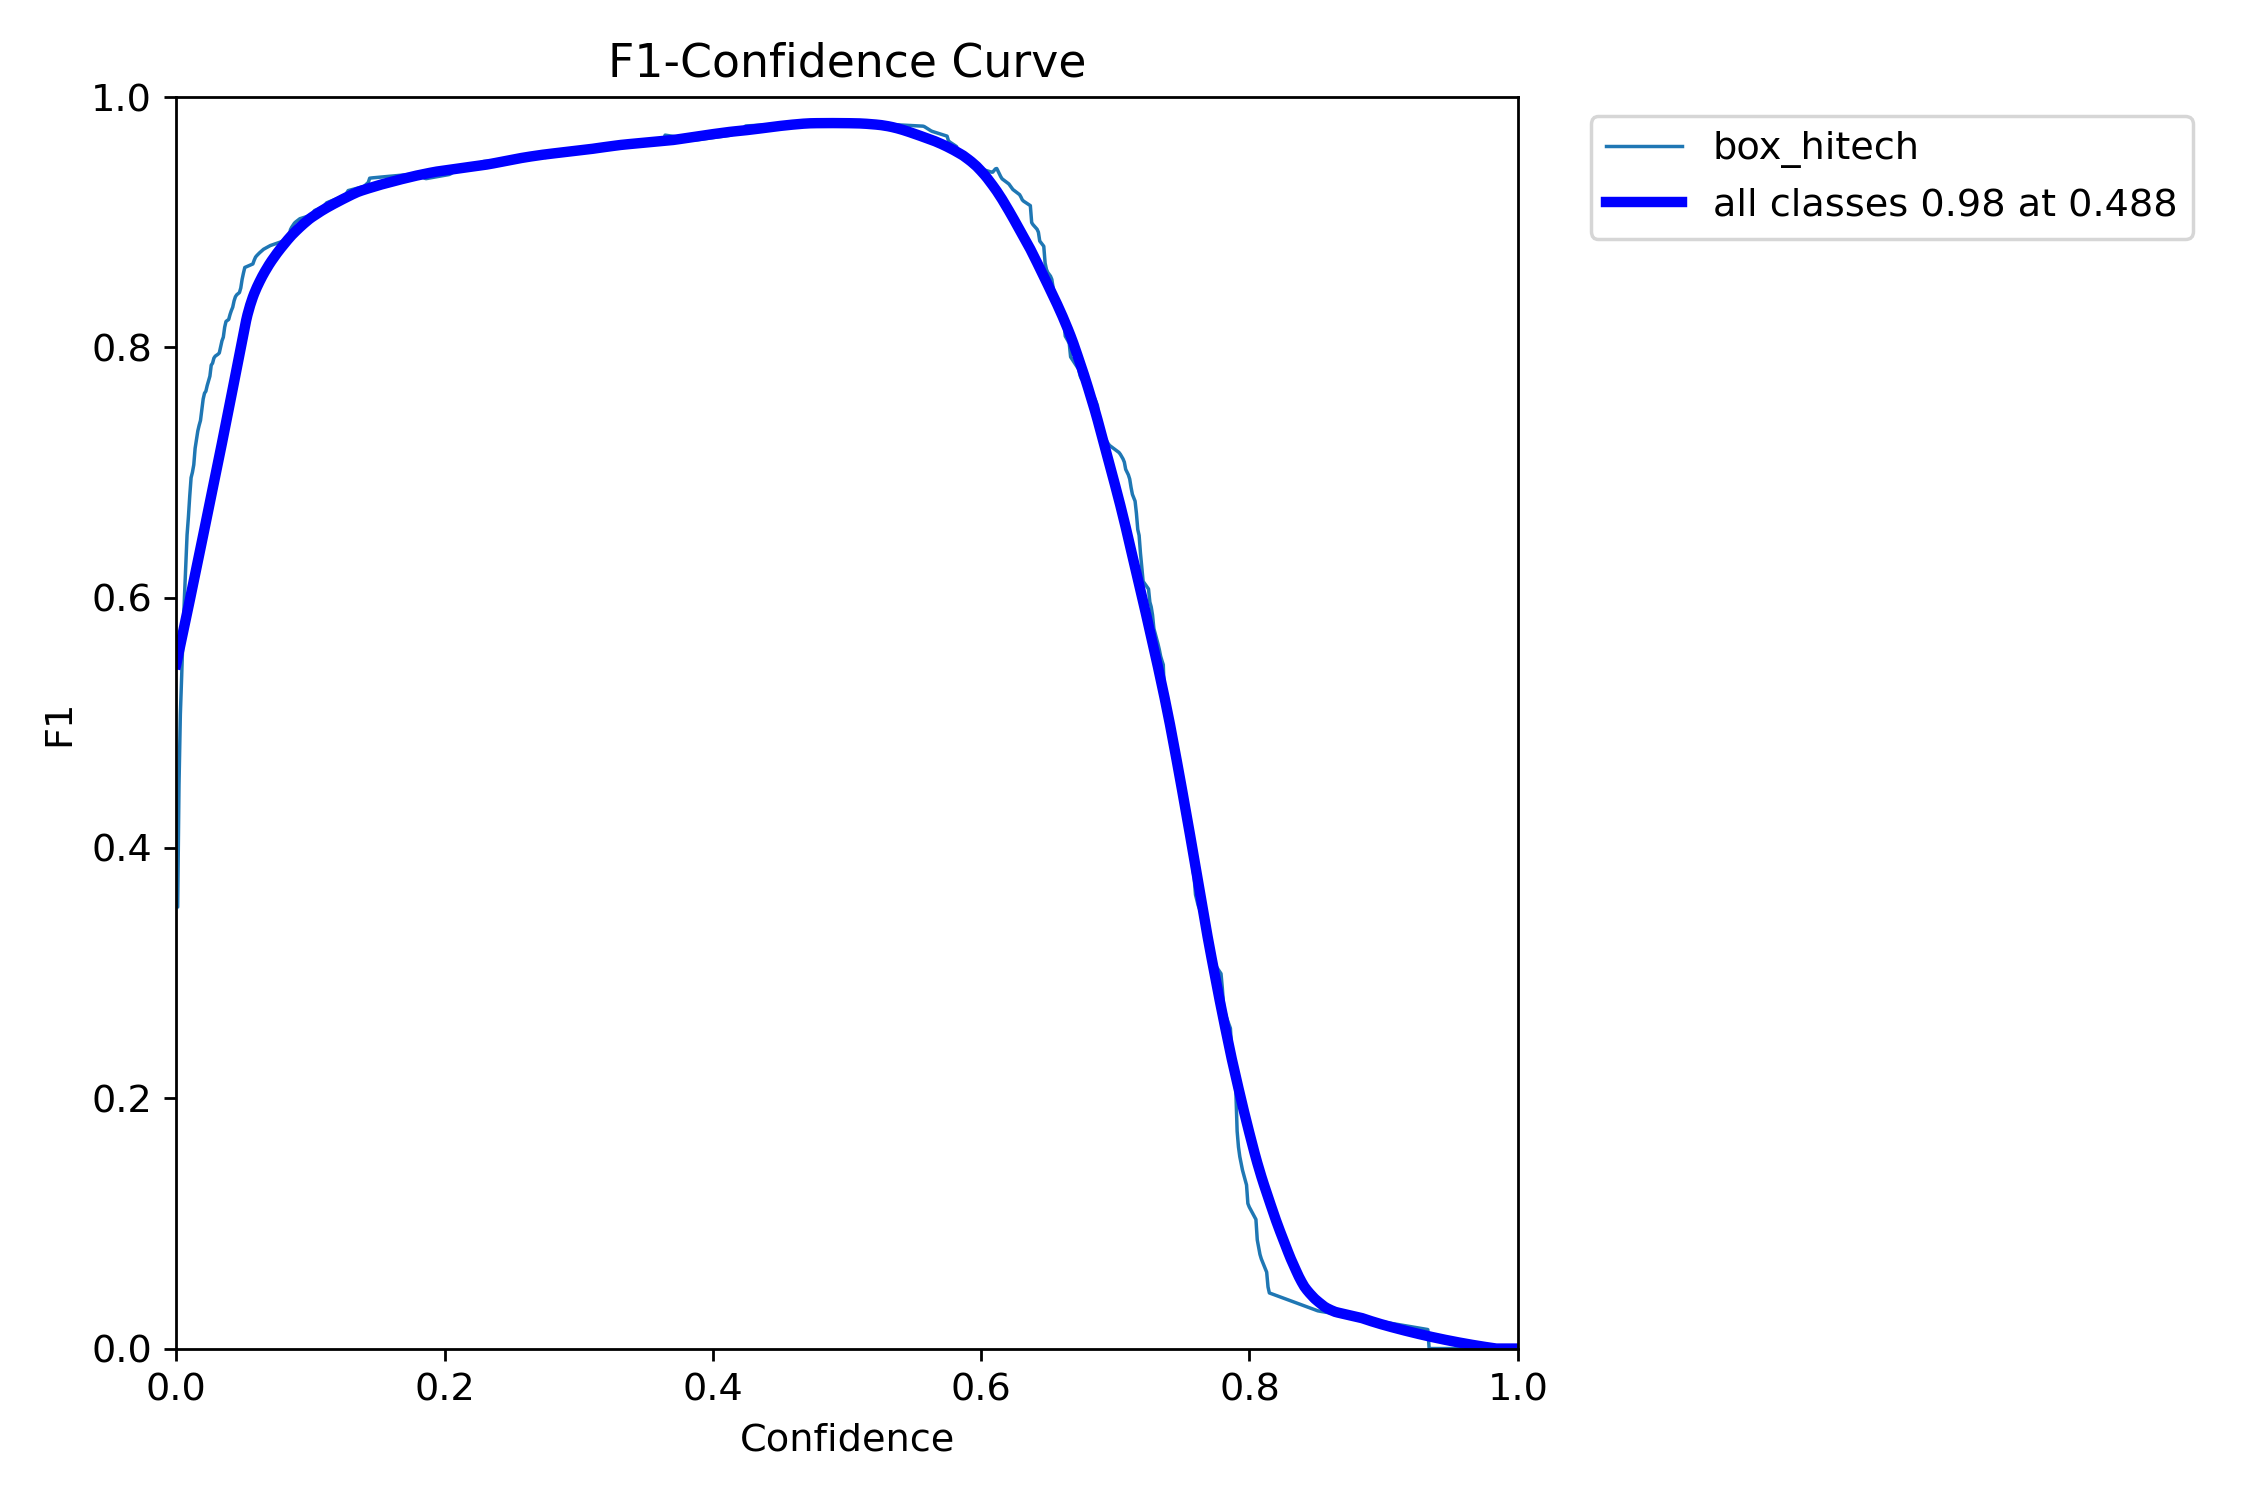

BoxP_curve.png


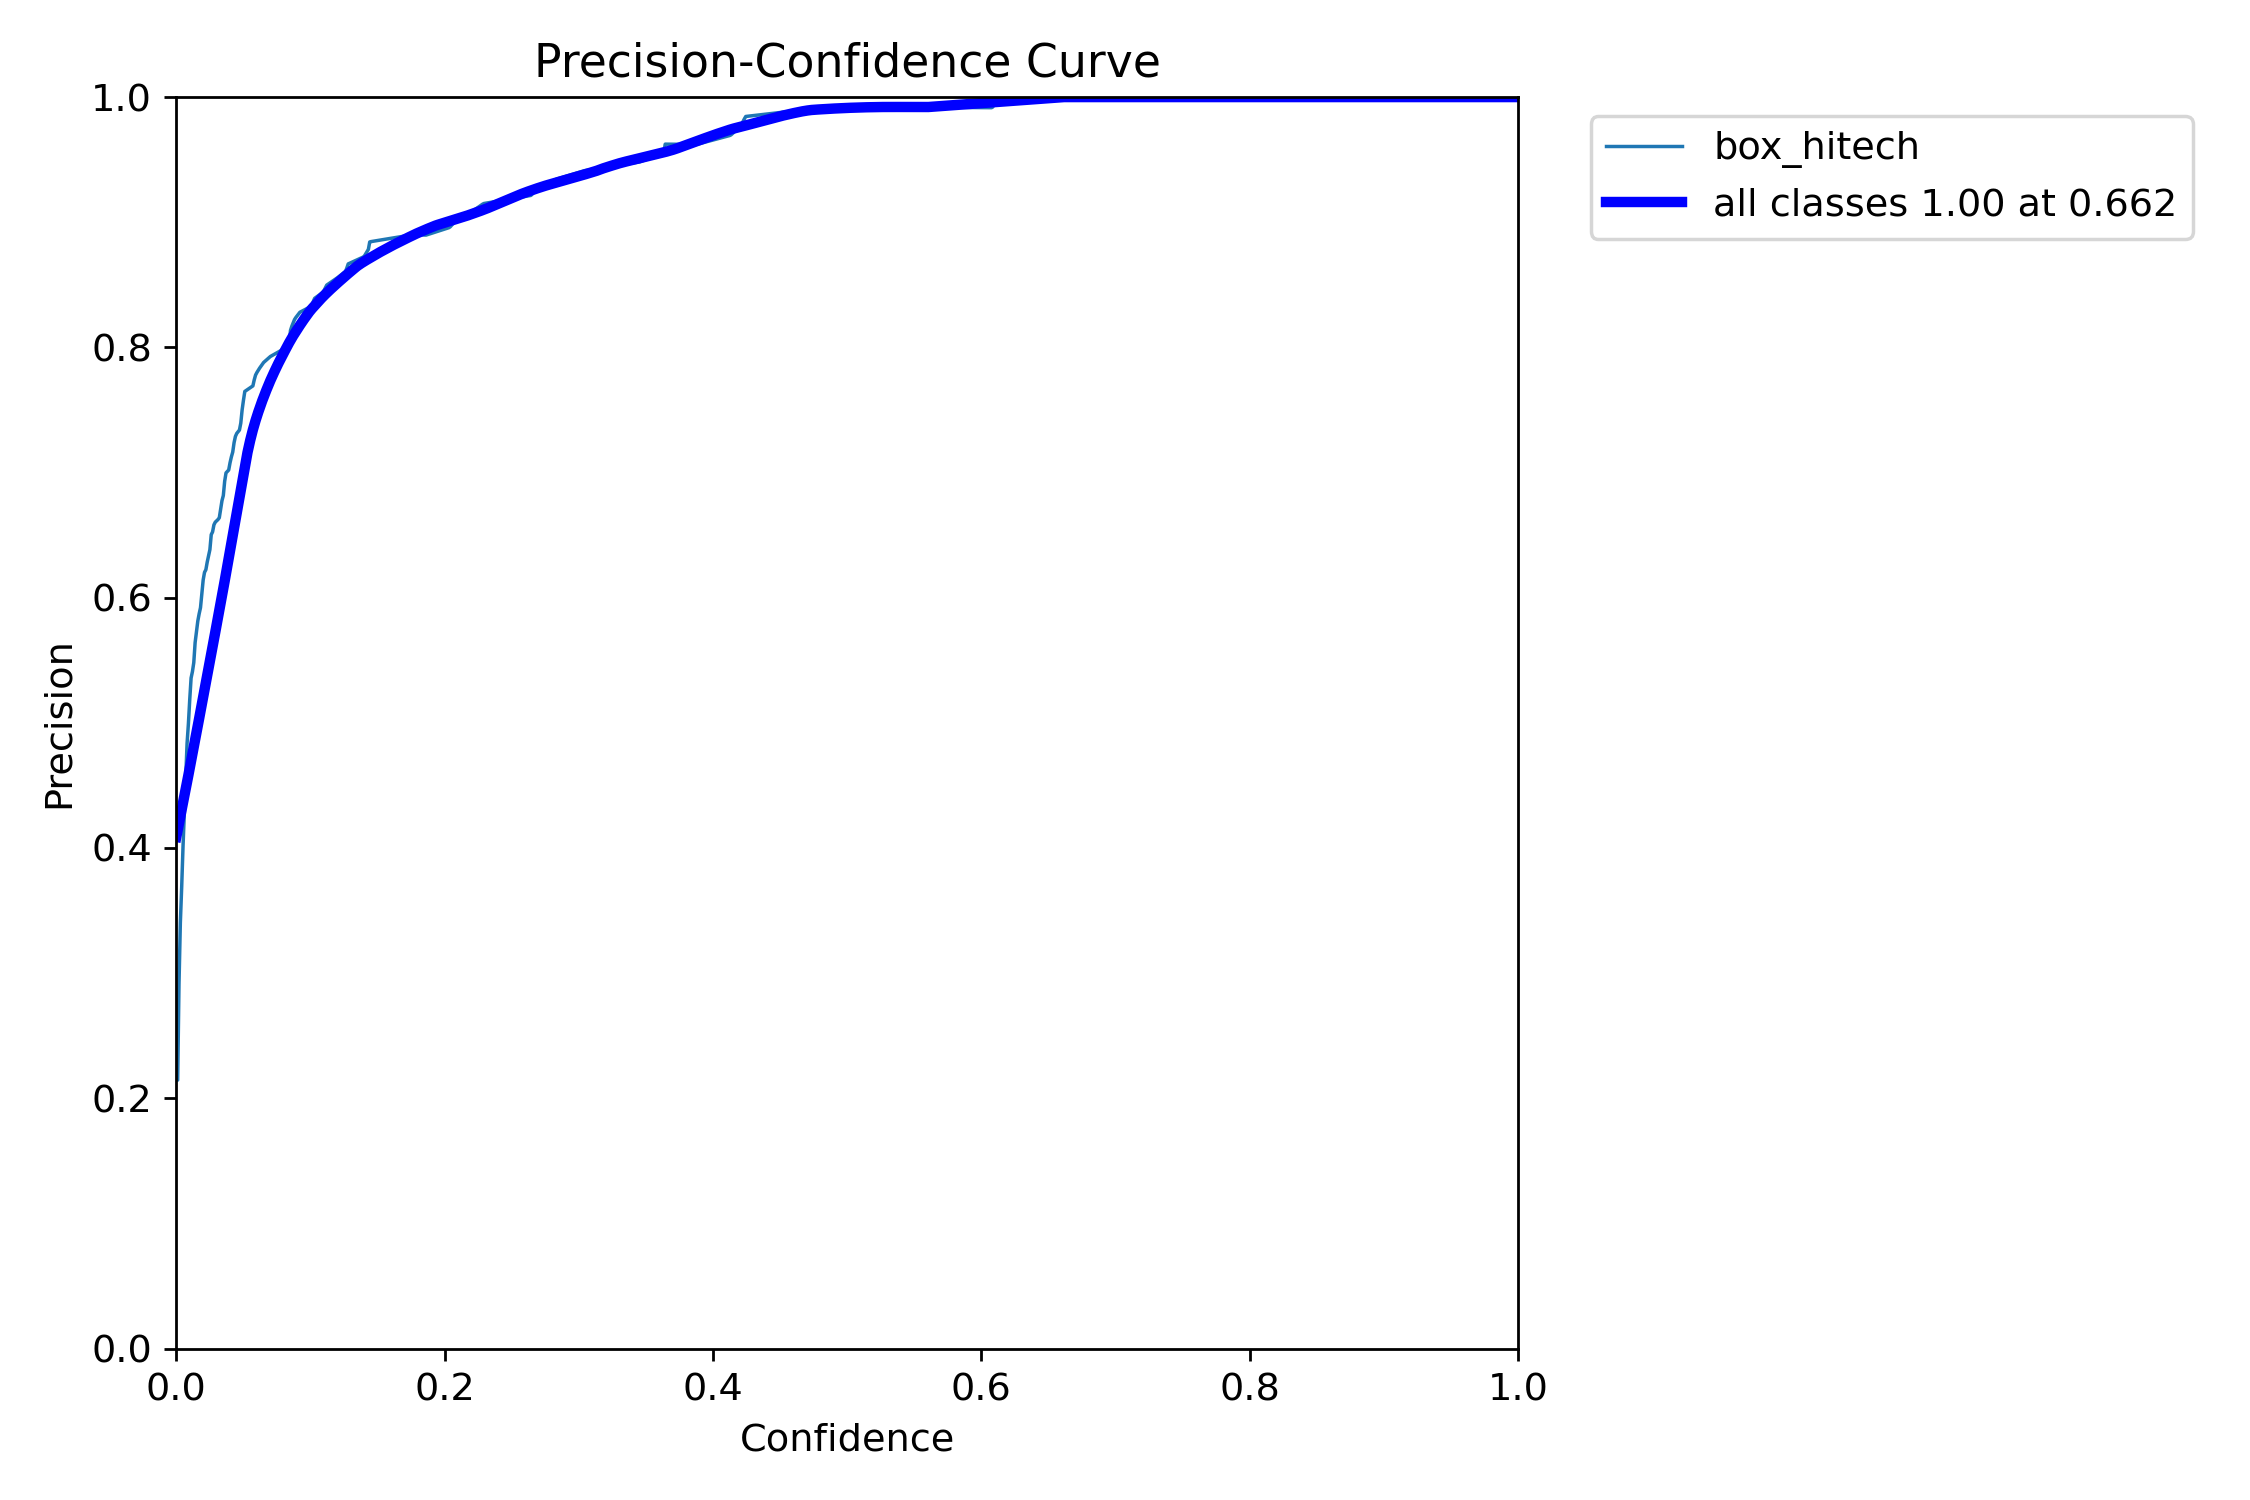

BoxR_curve.png


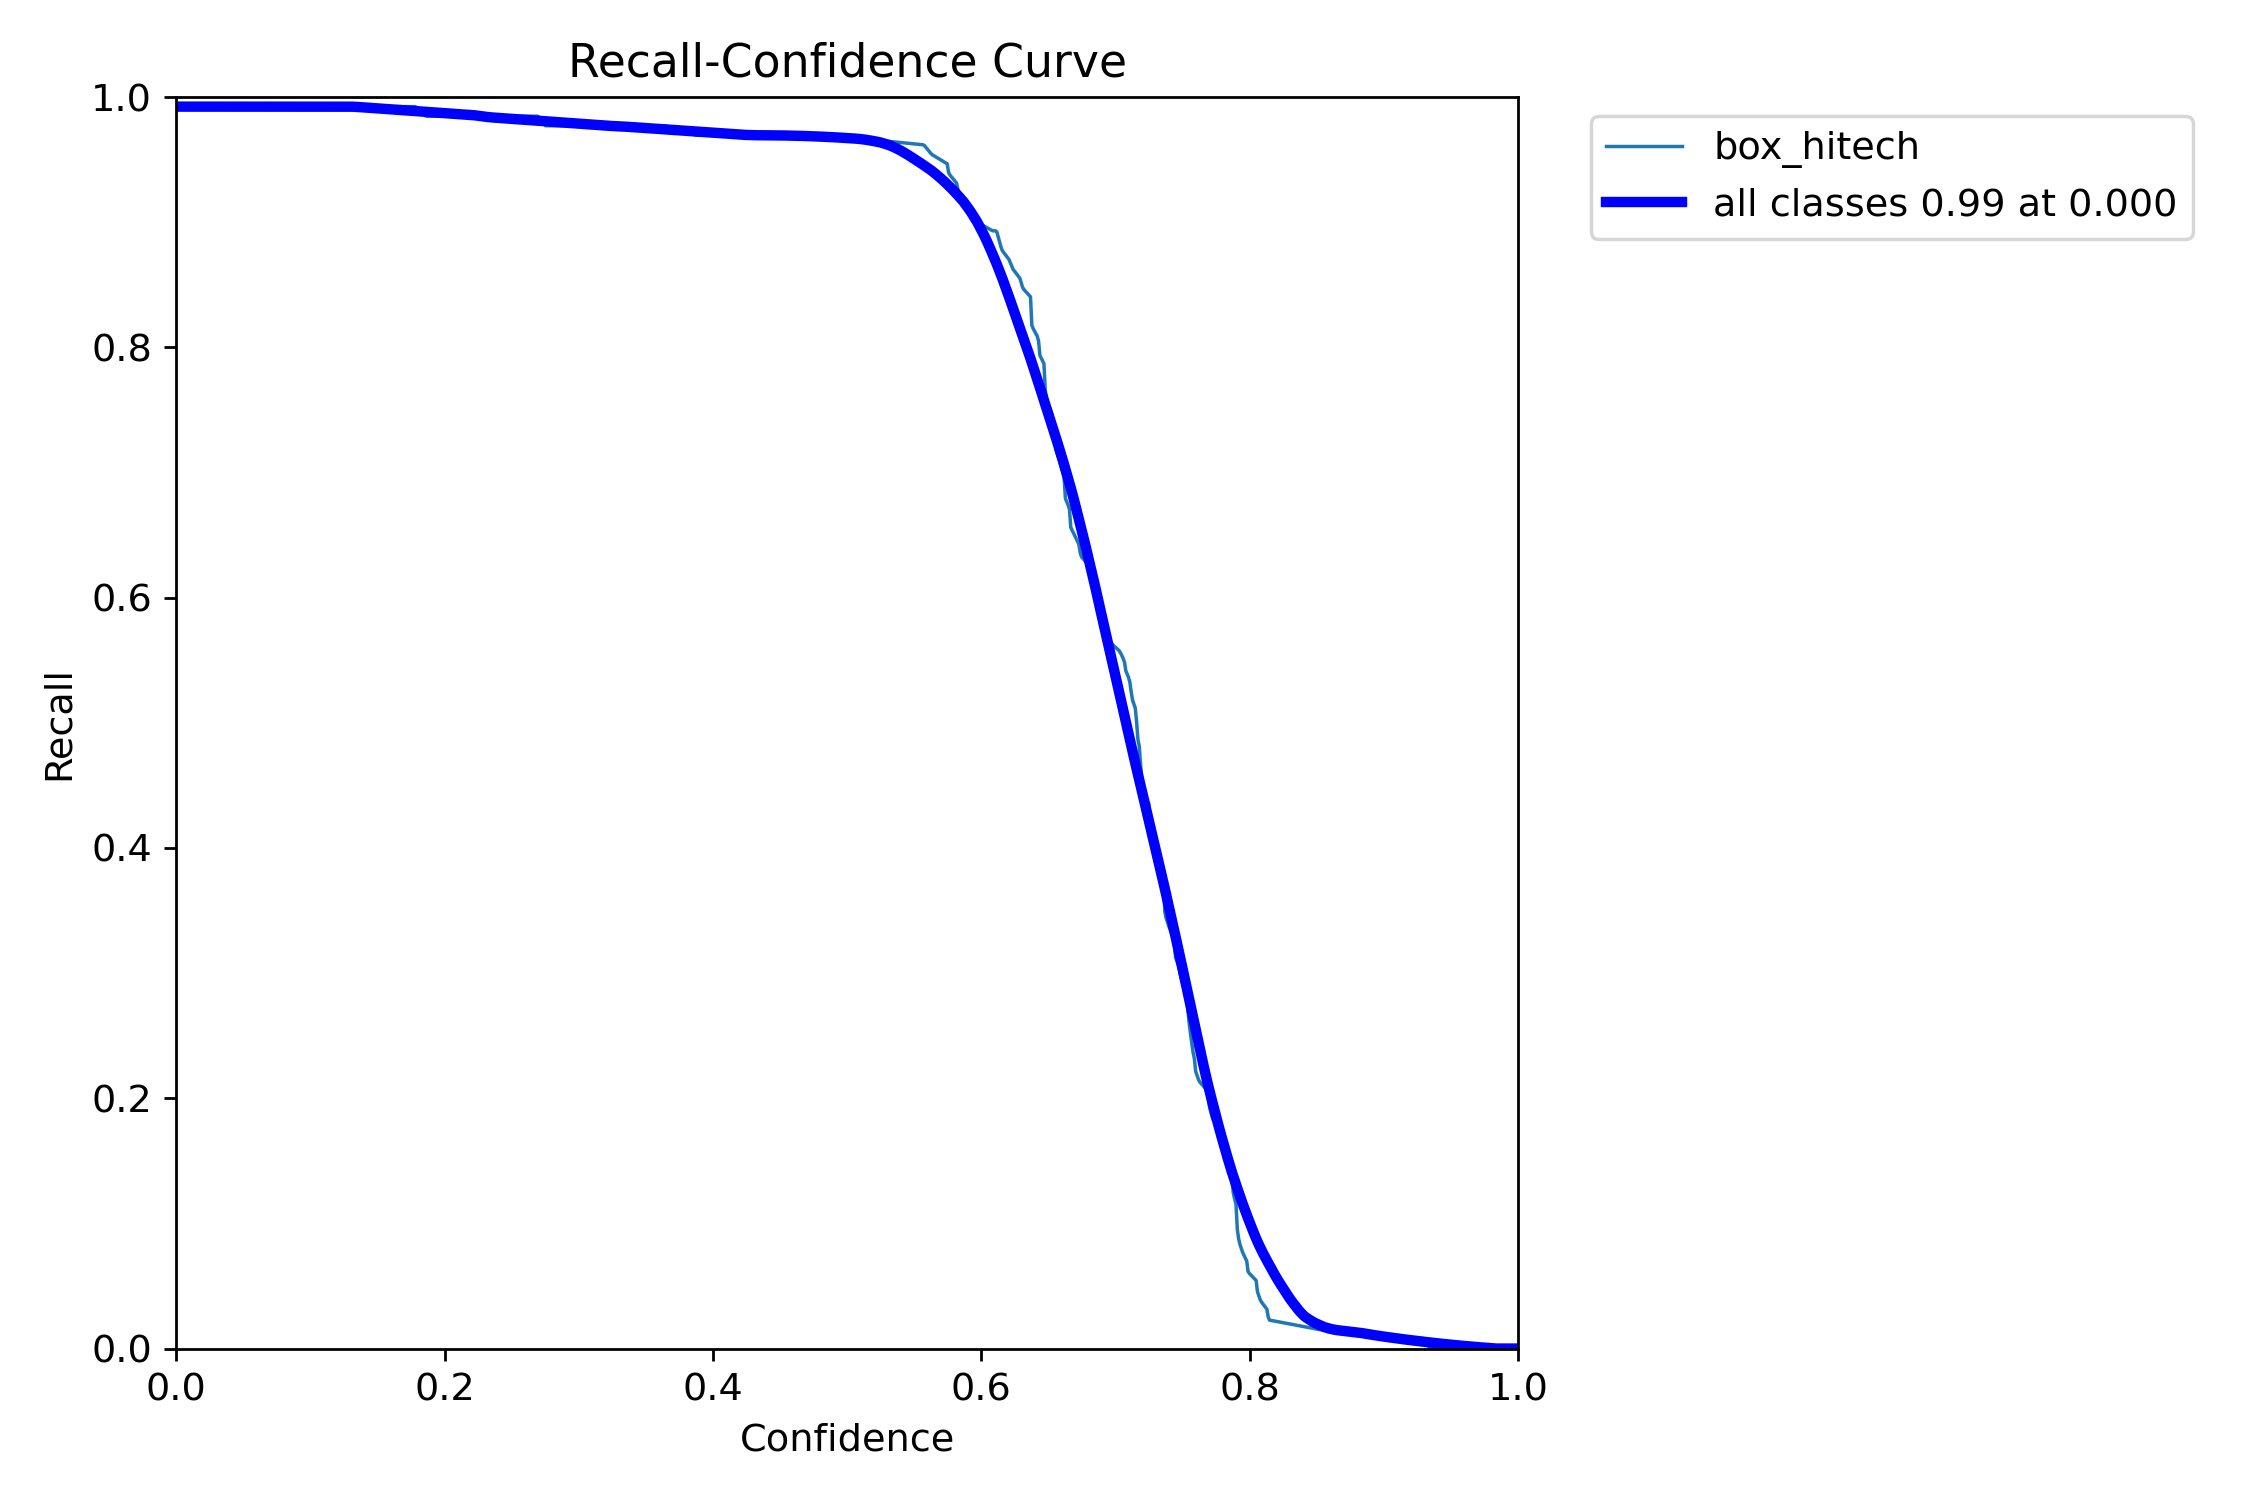

confusion_matrix.png


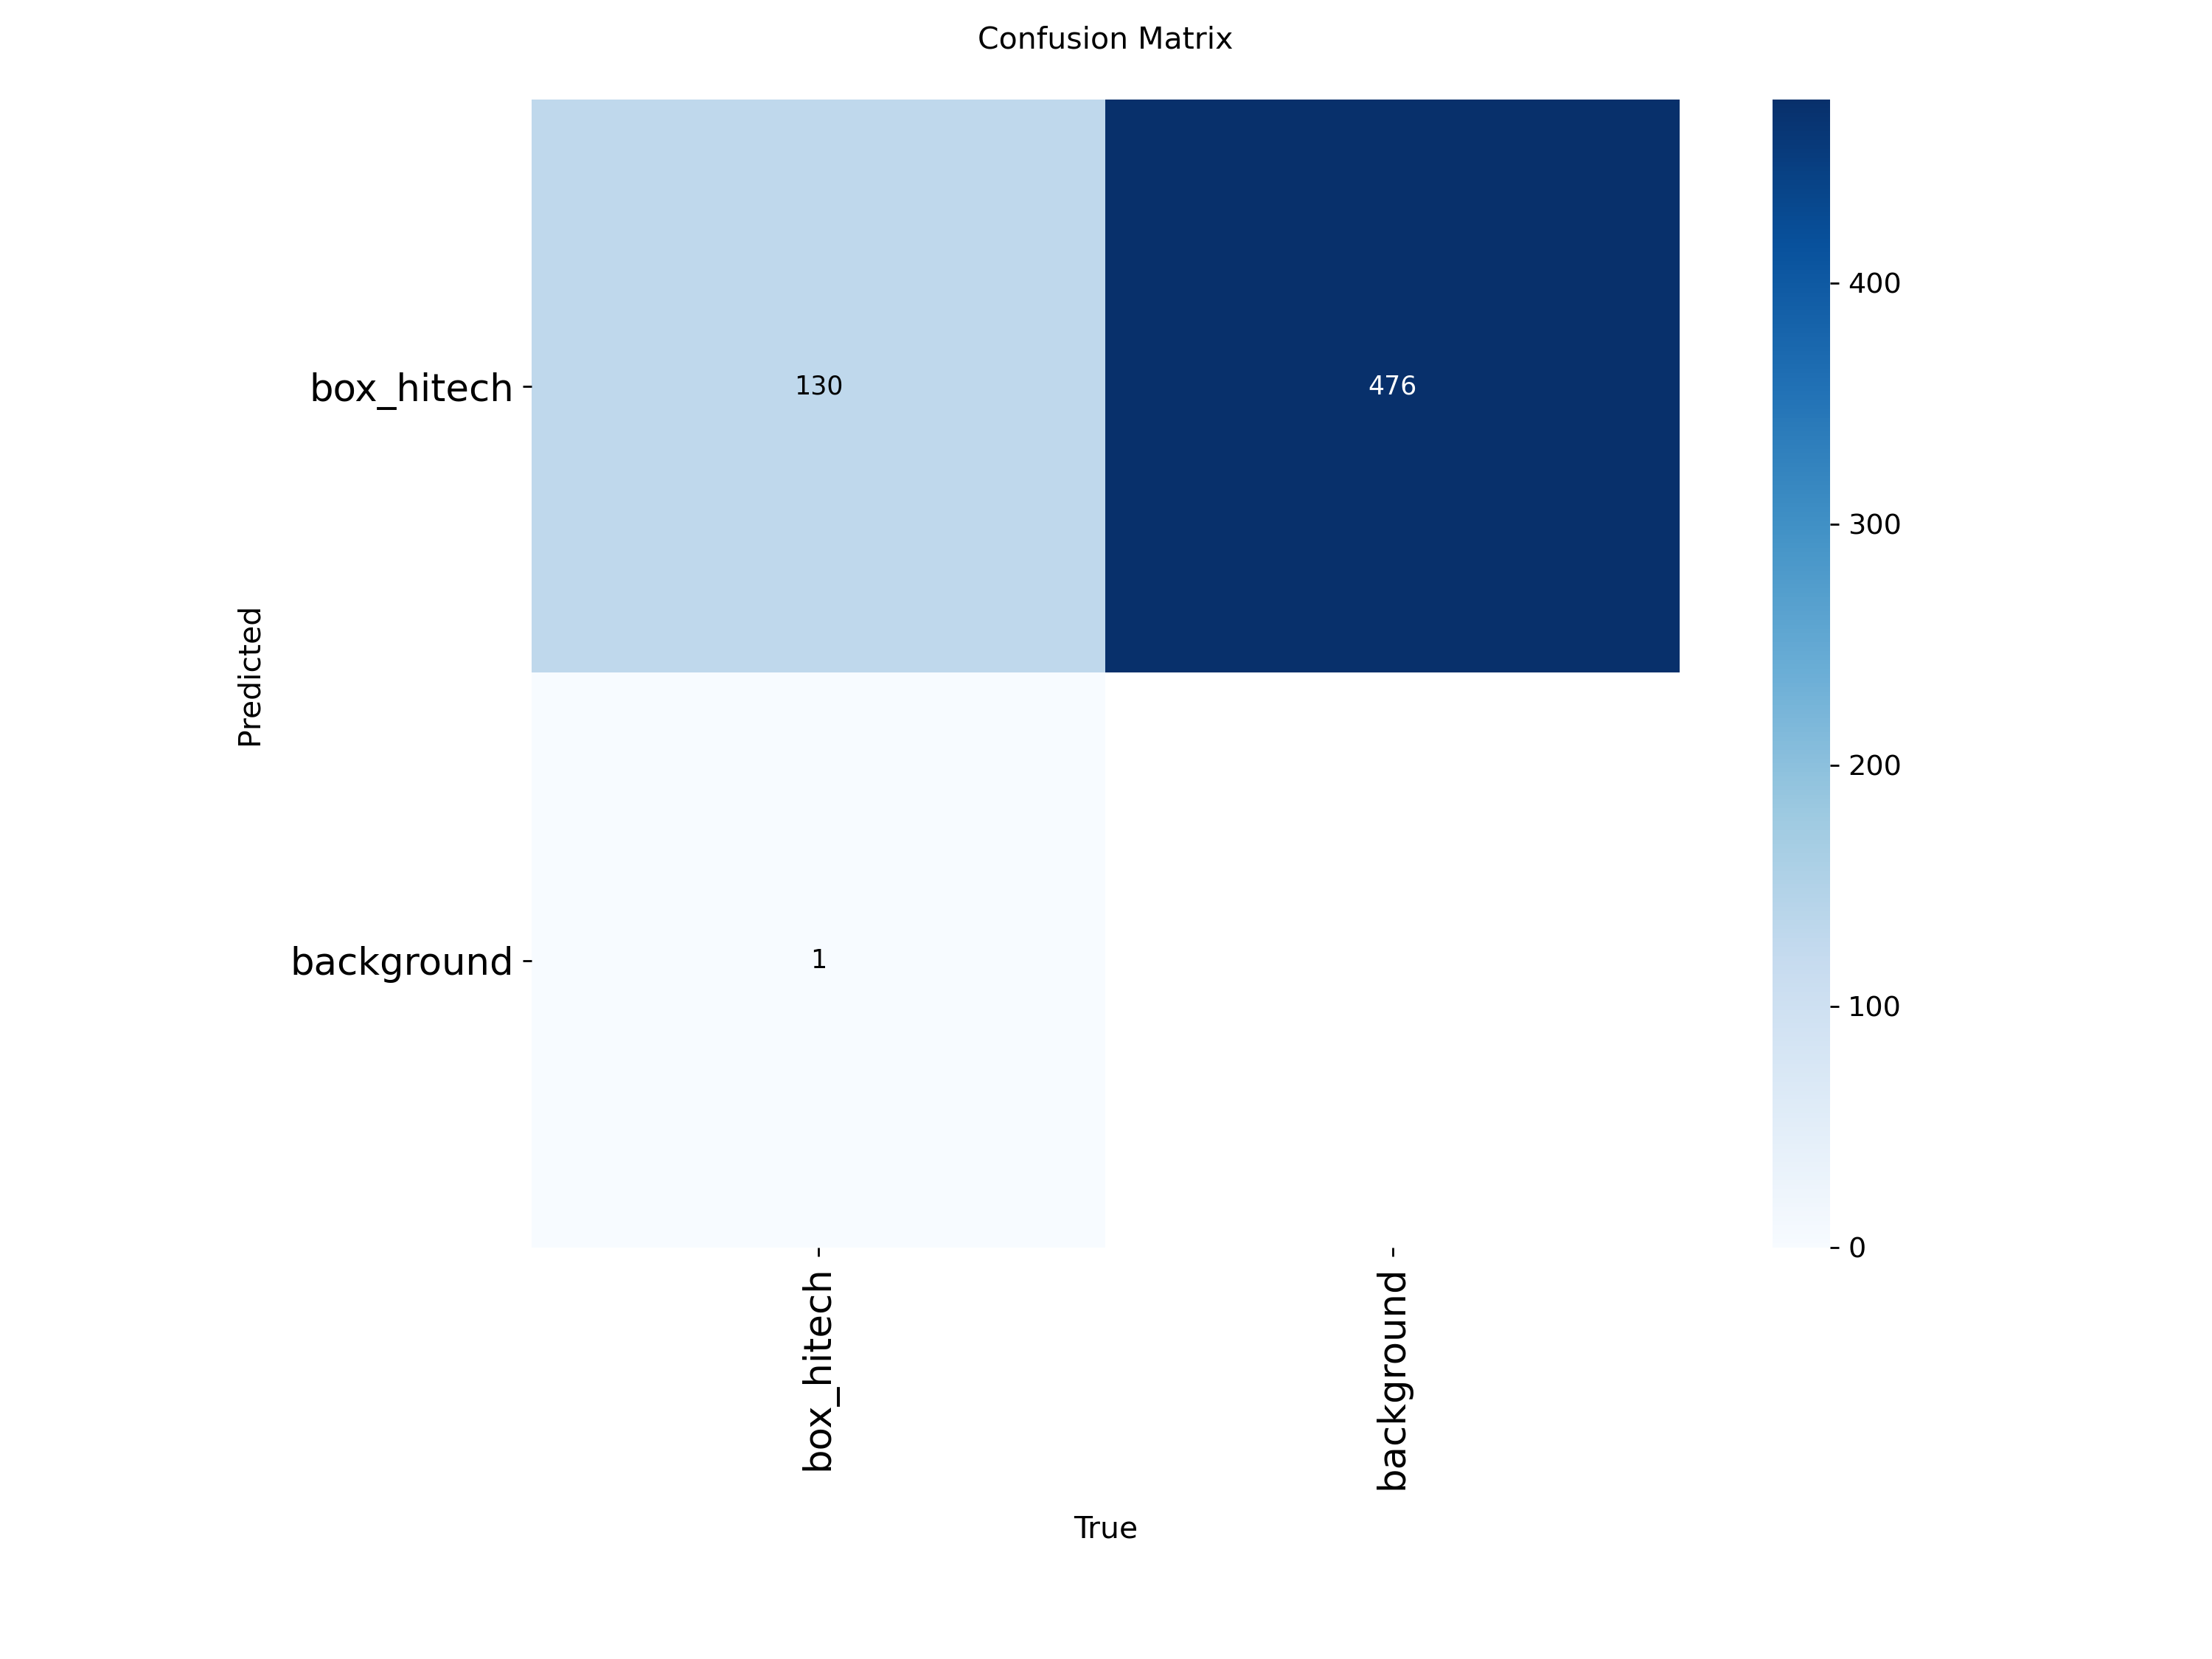

confusion_matrix_normalized.png


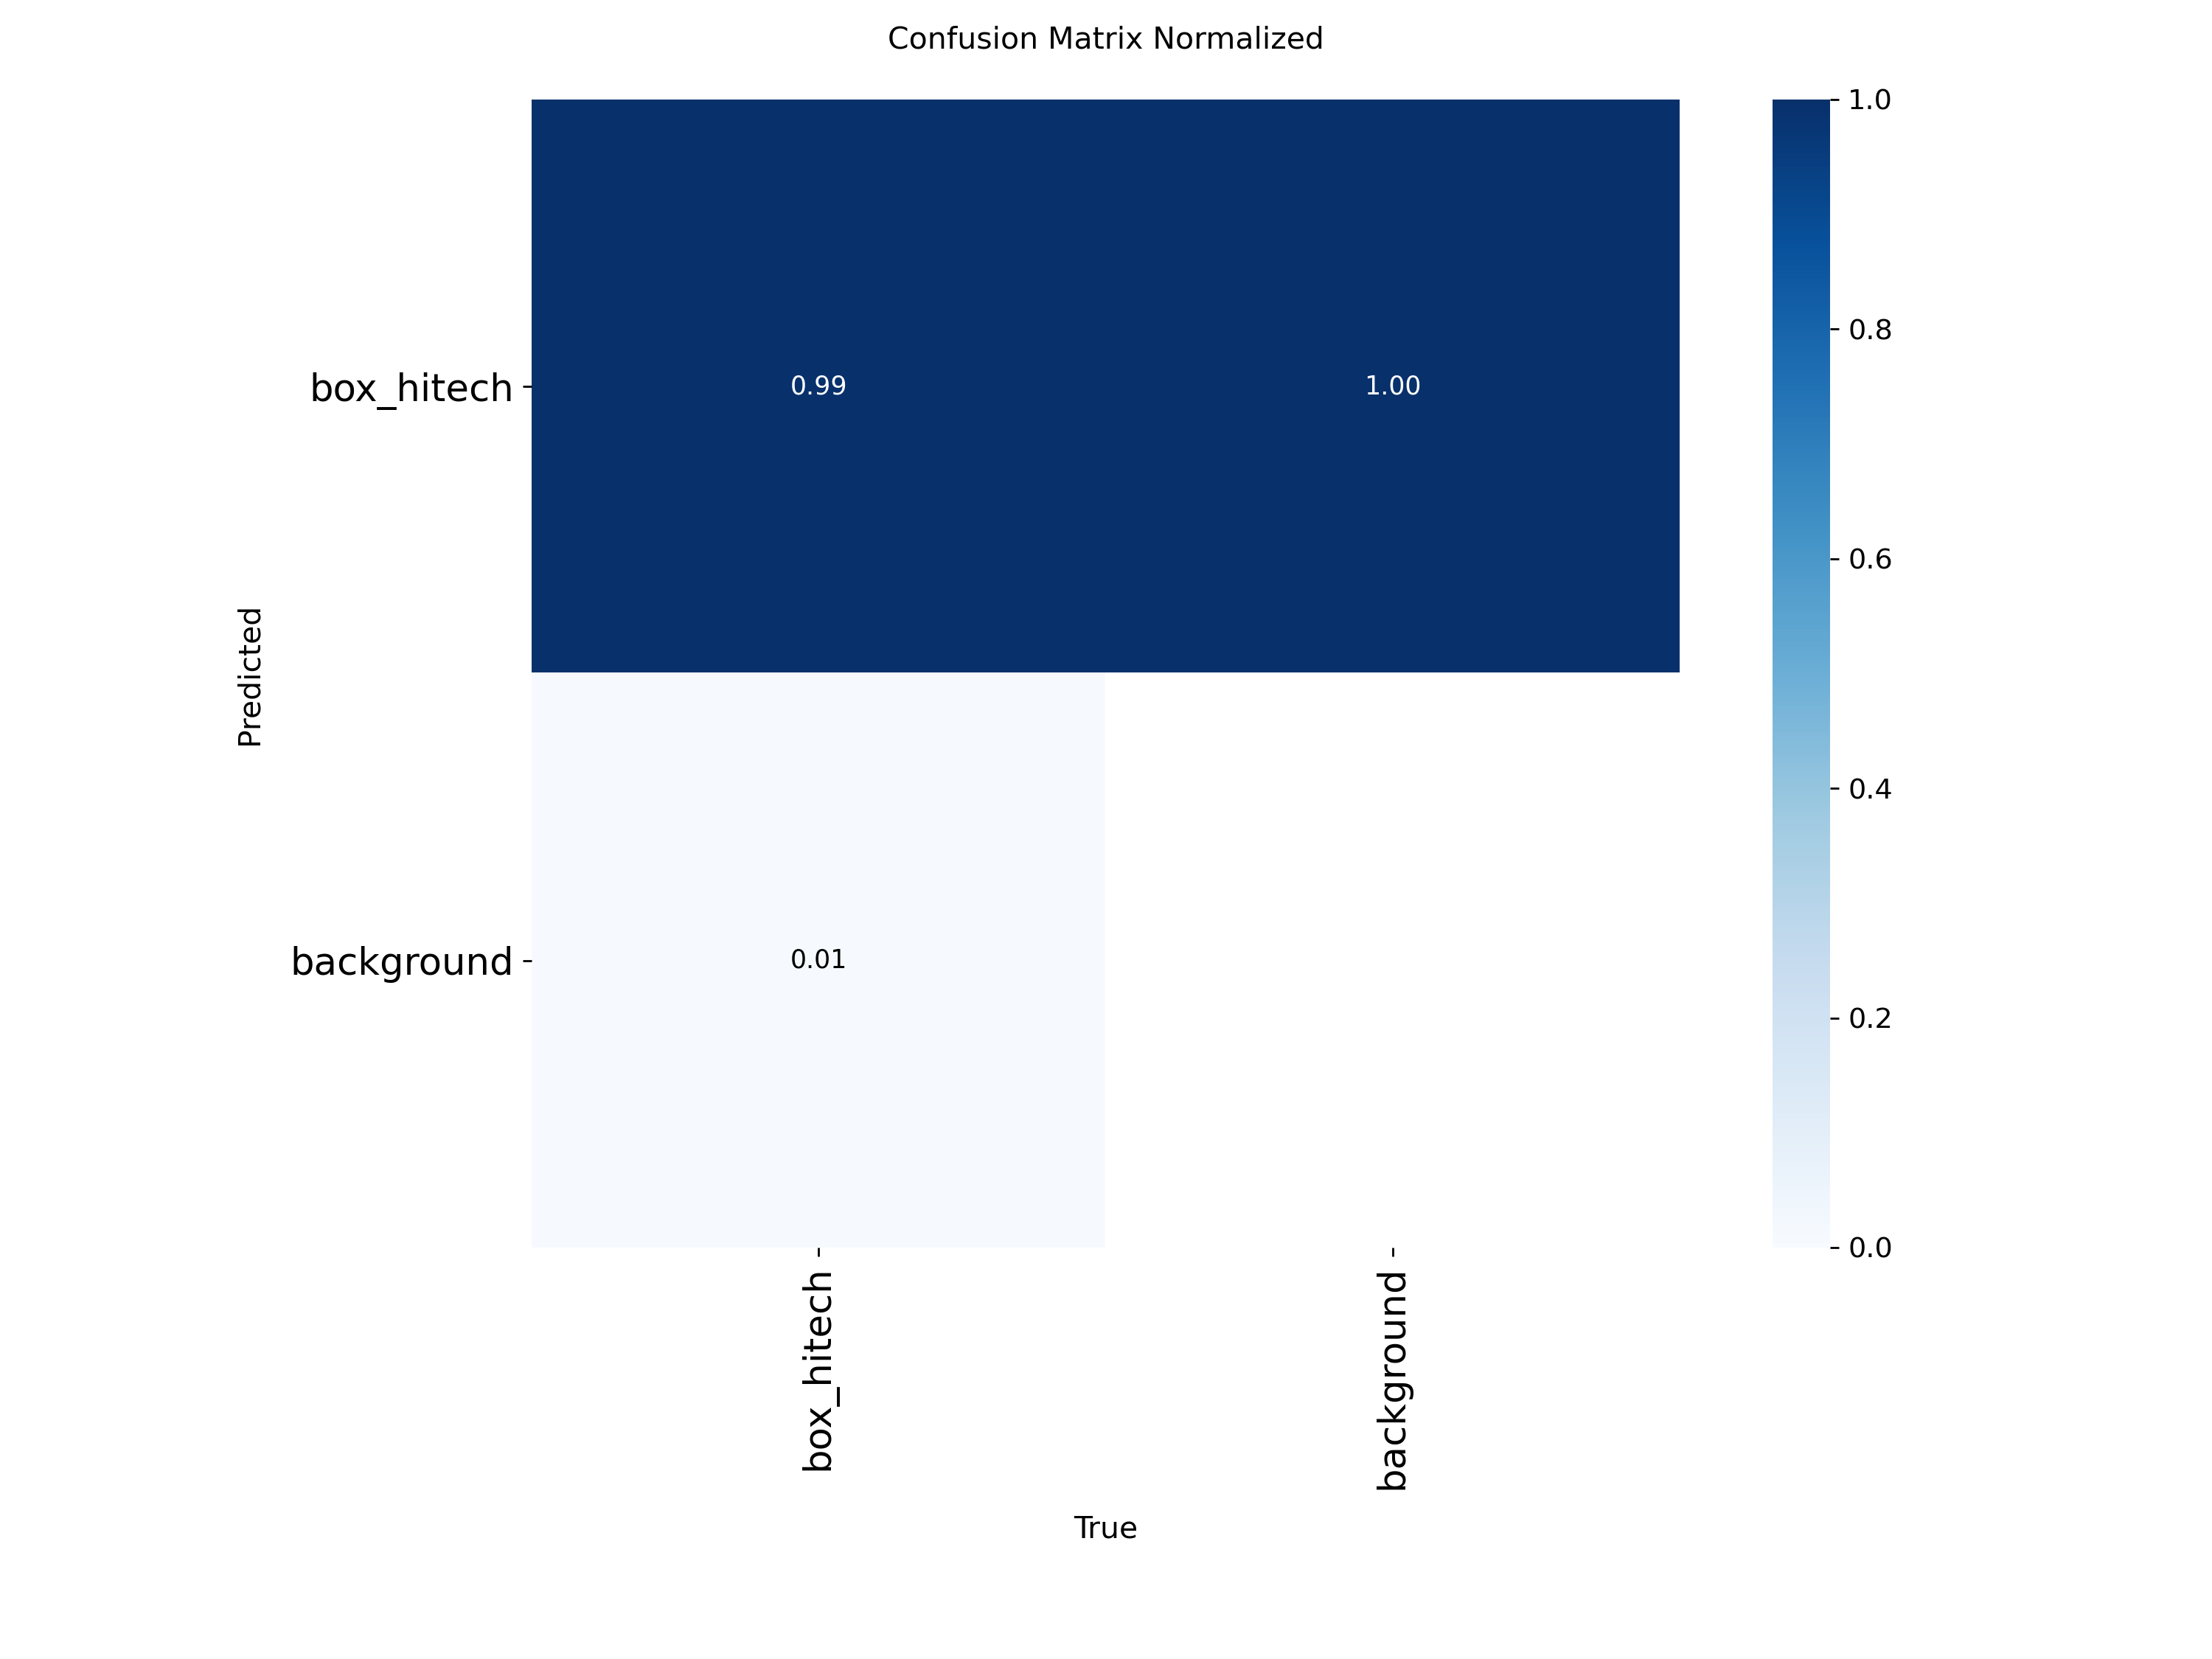

train_batch0.jpg


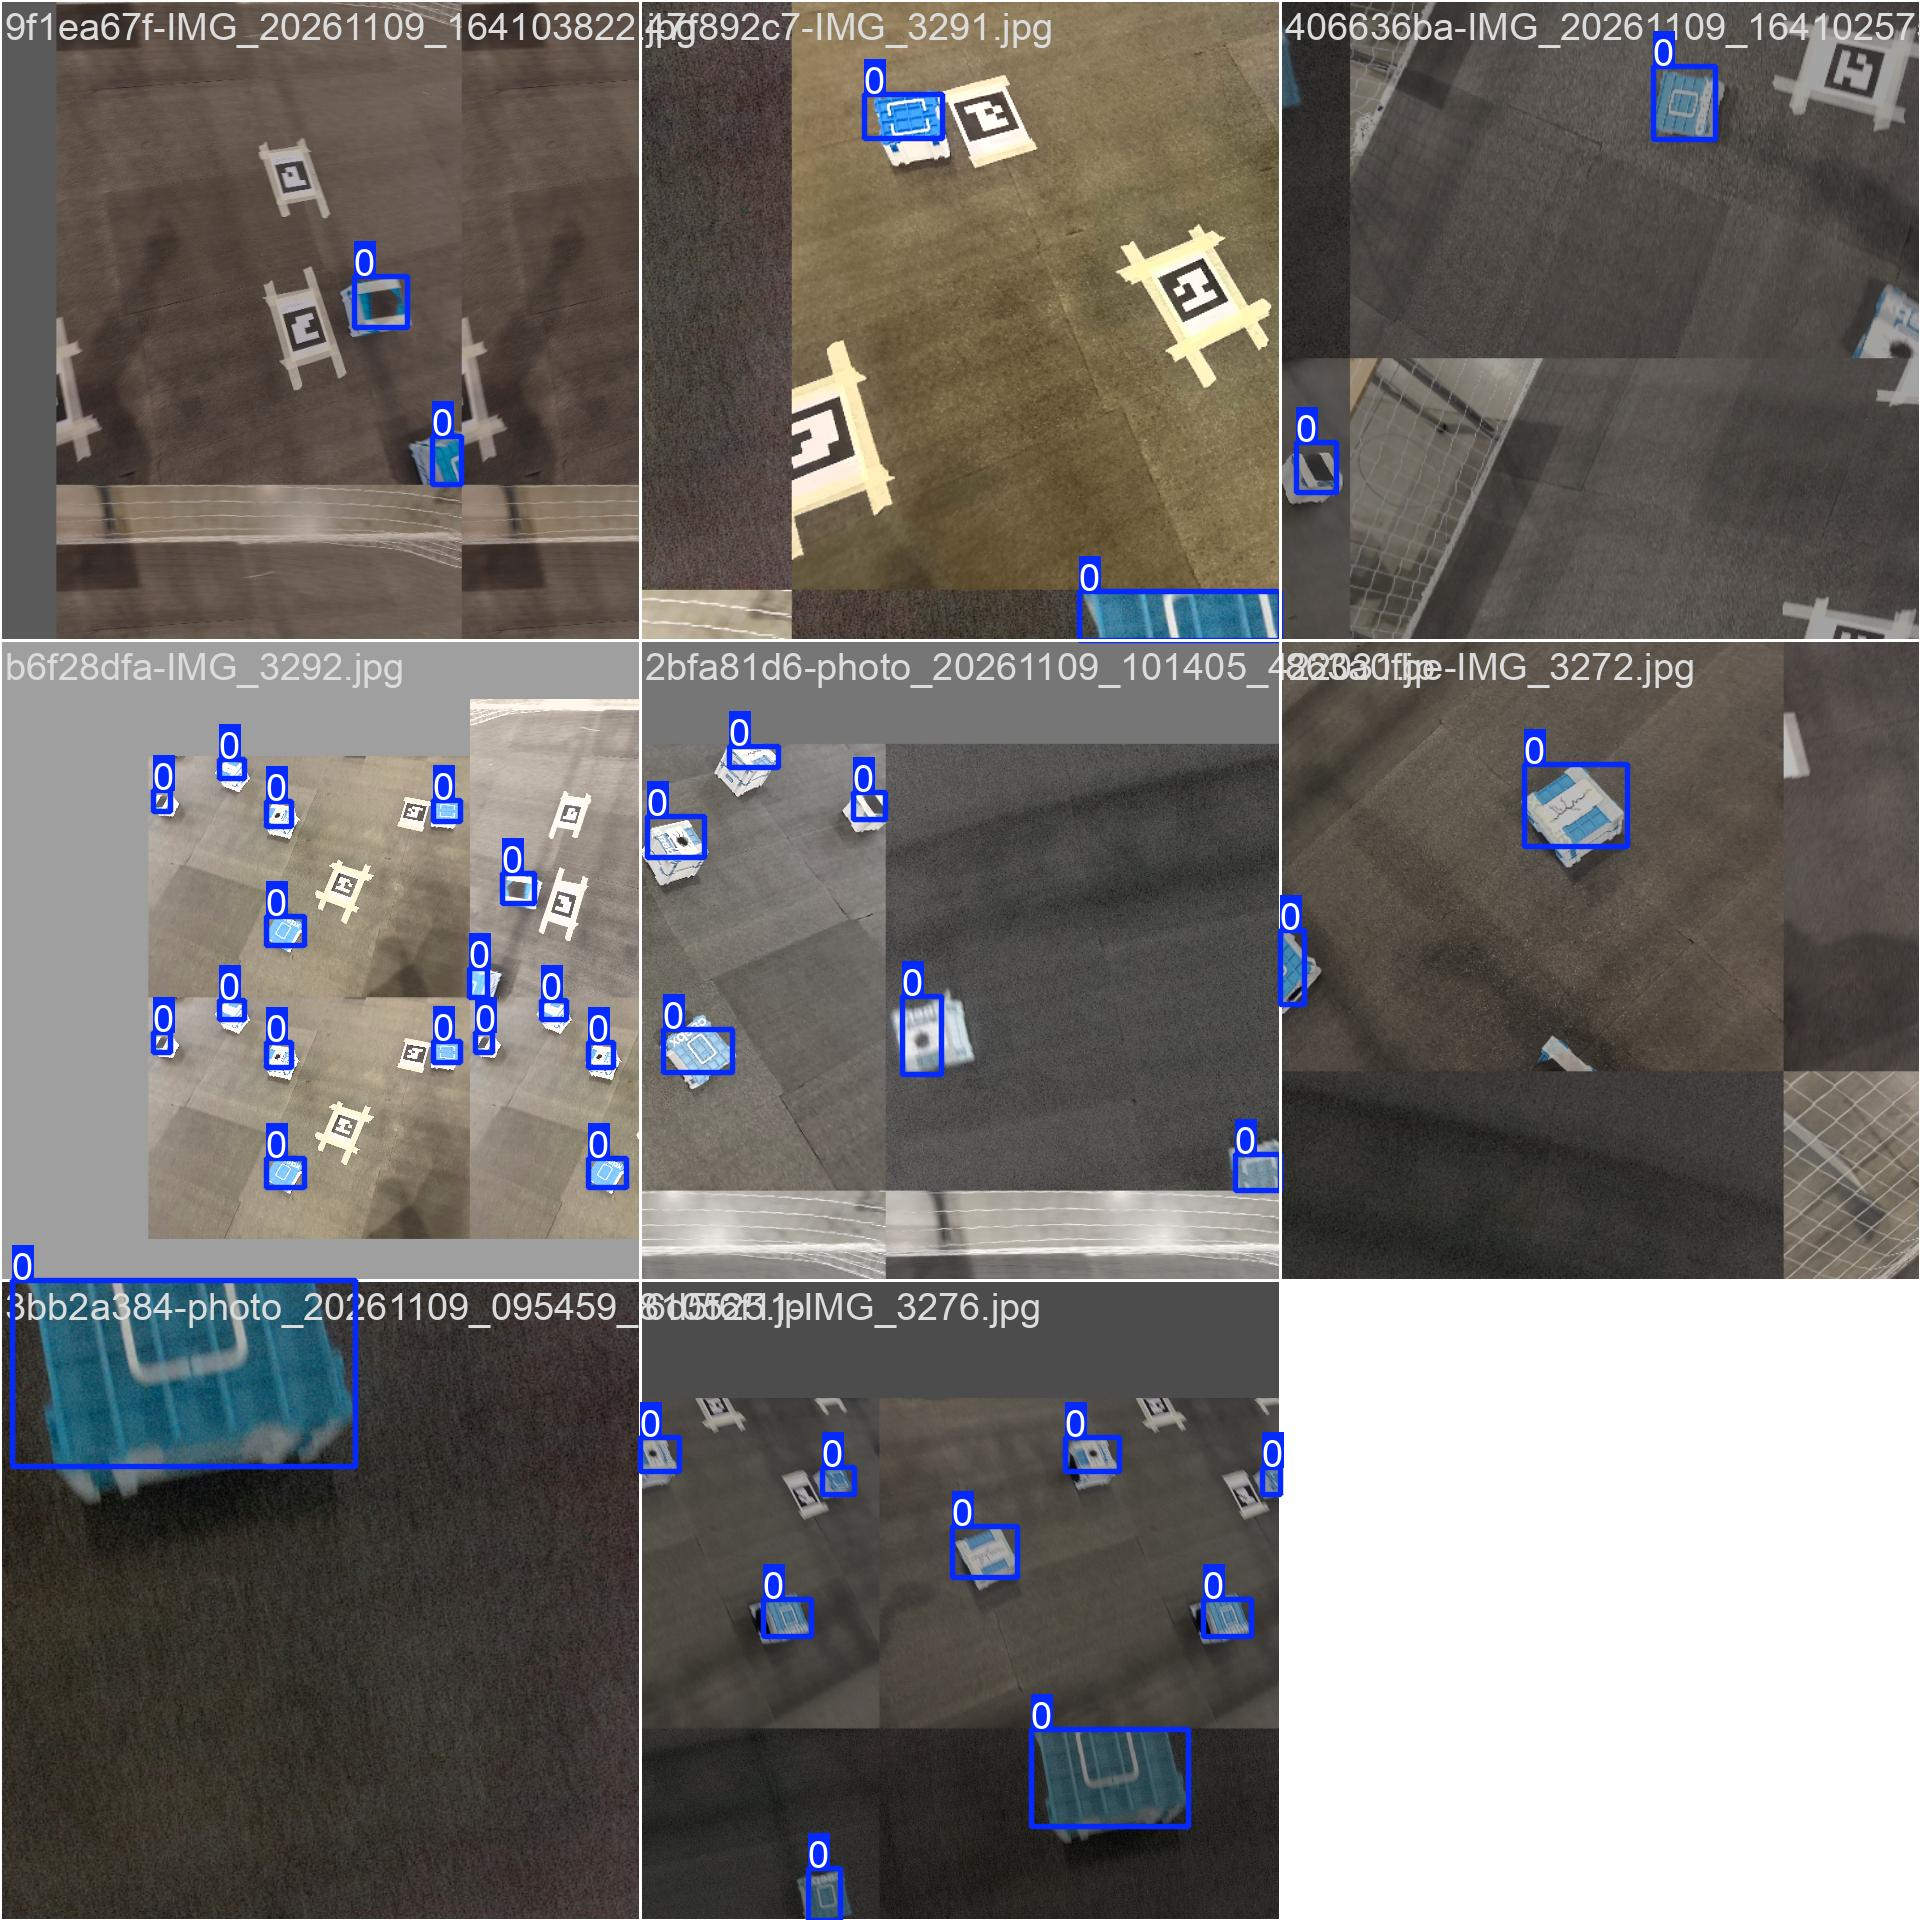

train_batch1.jpg


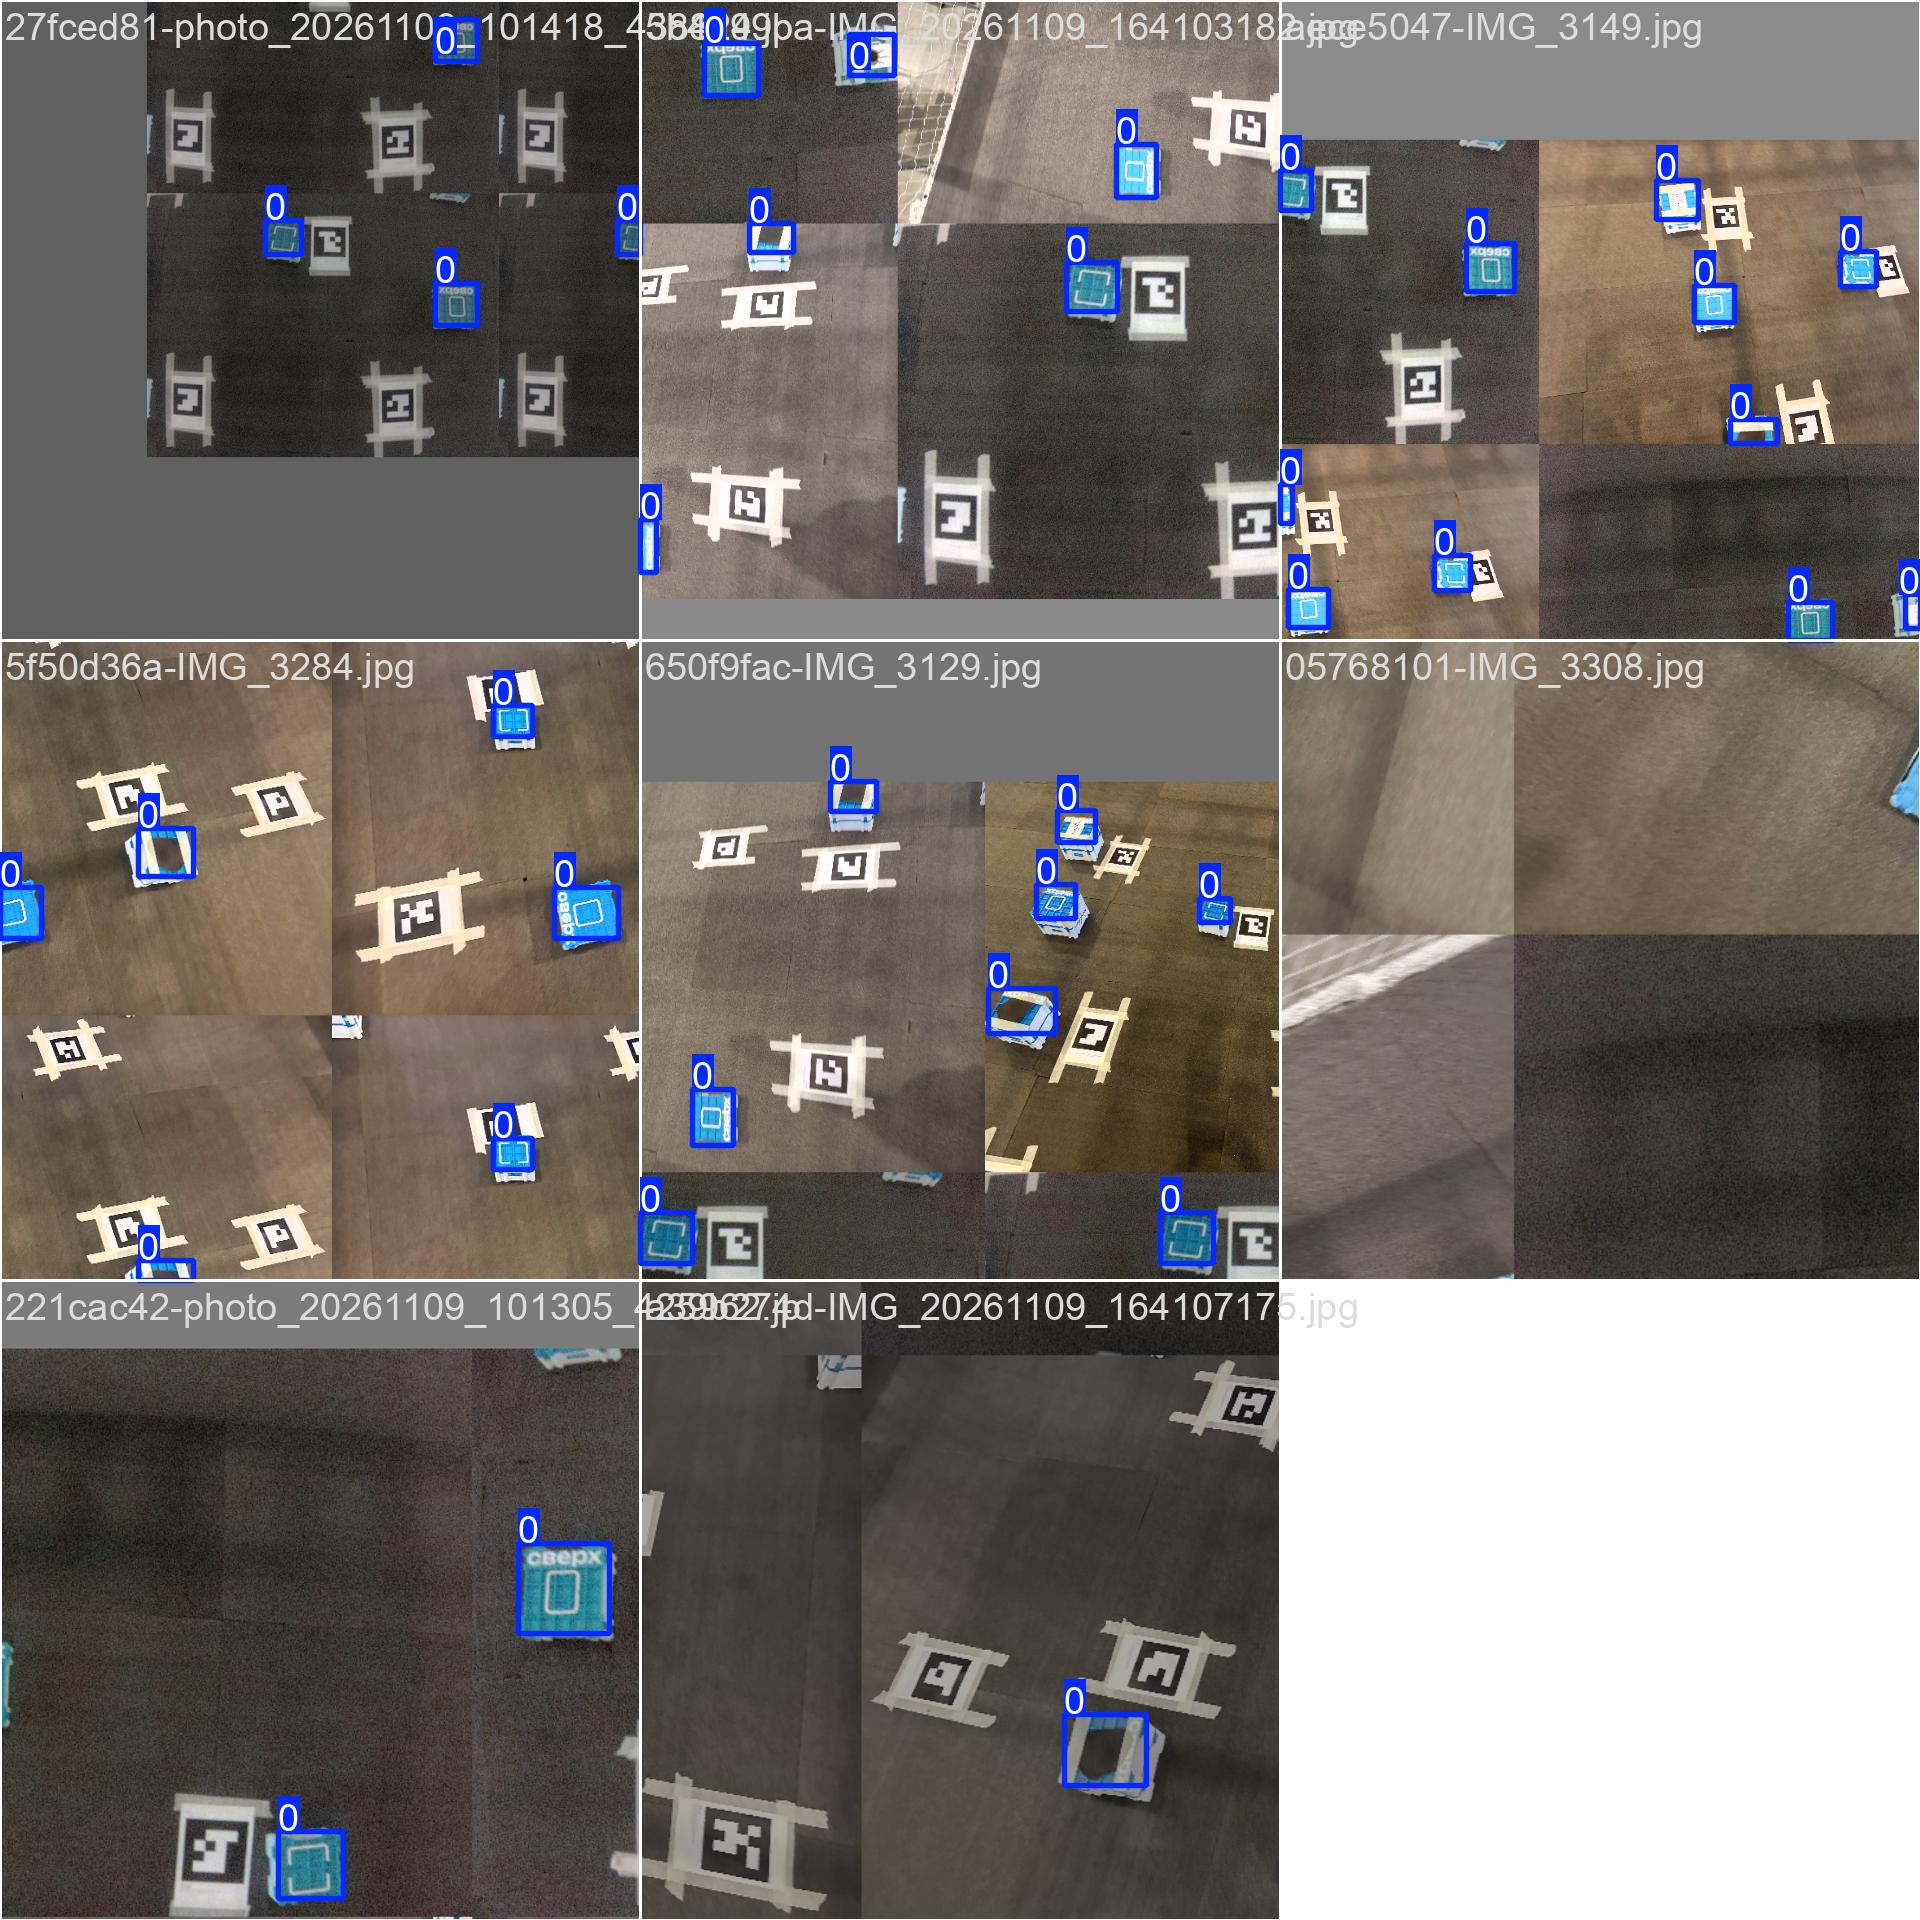

train_batch2.jpg


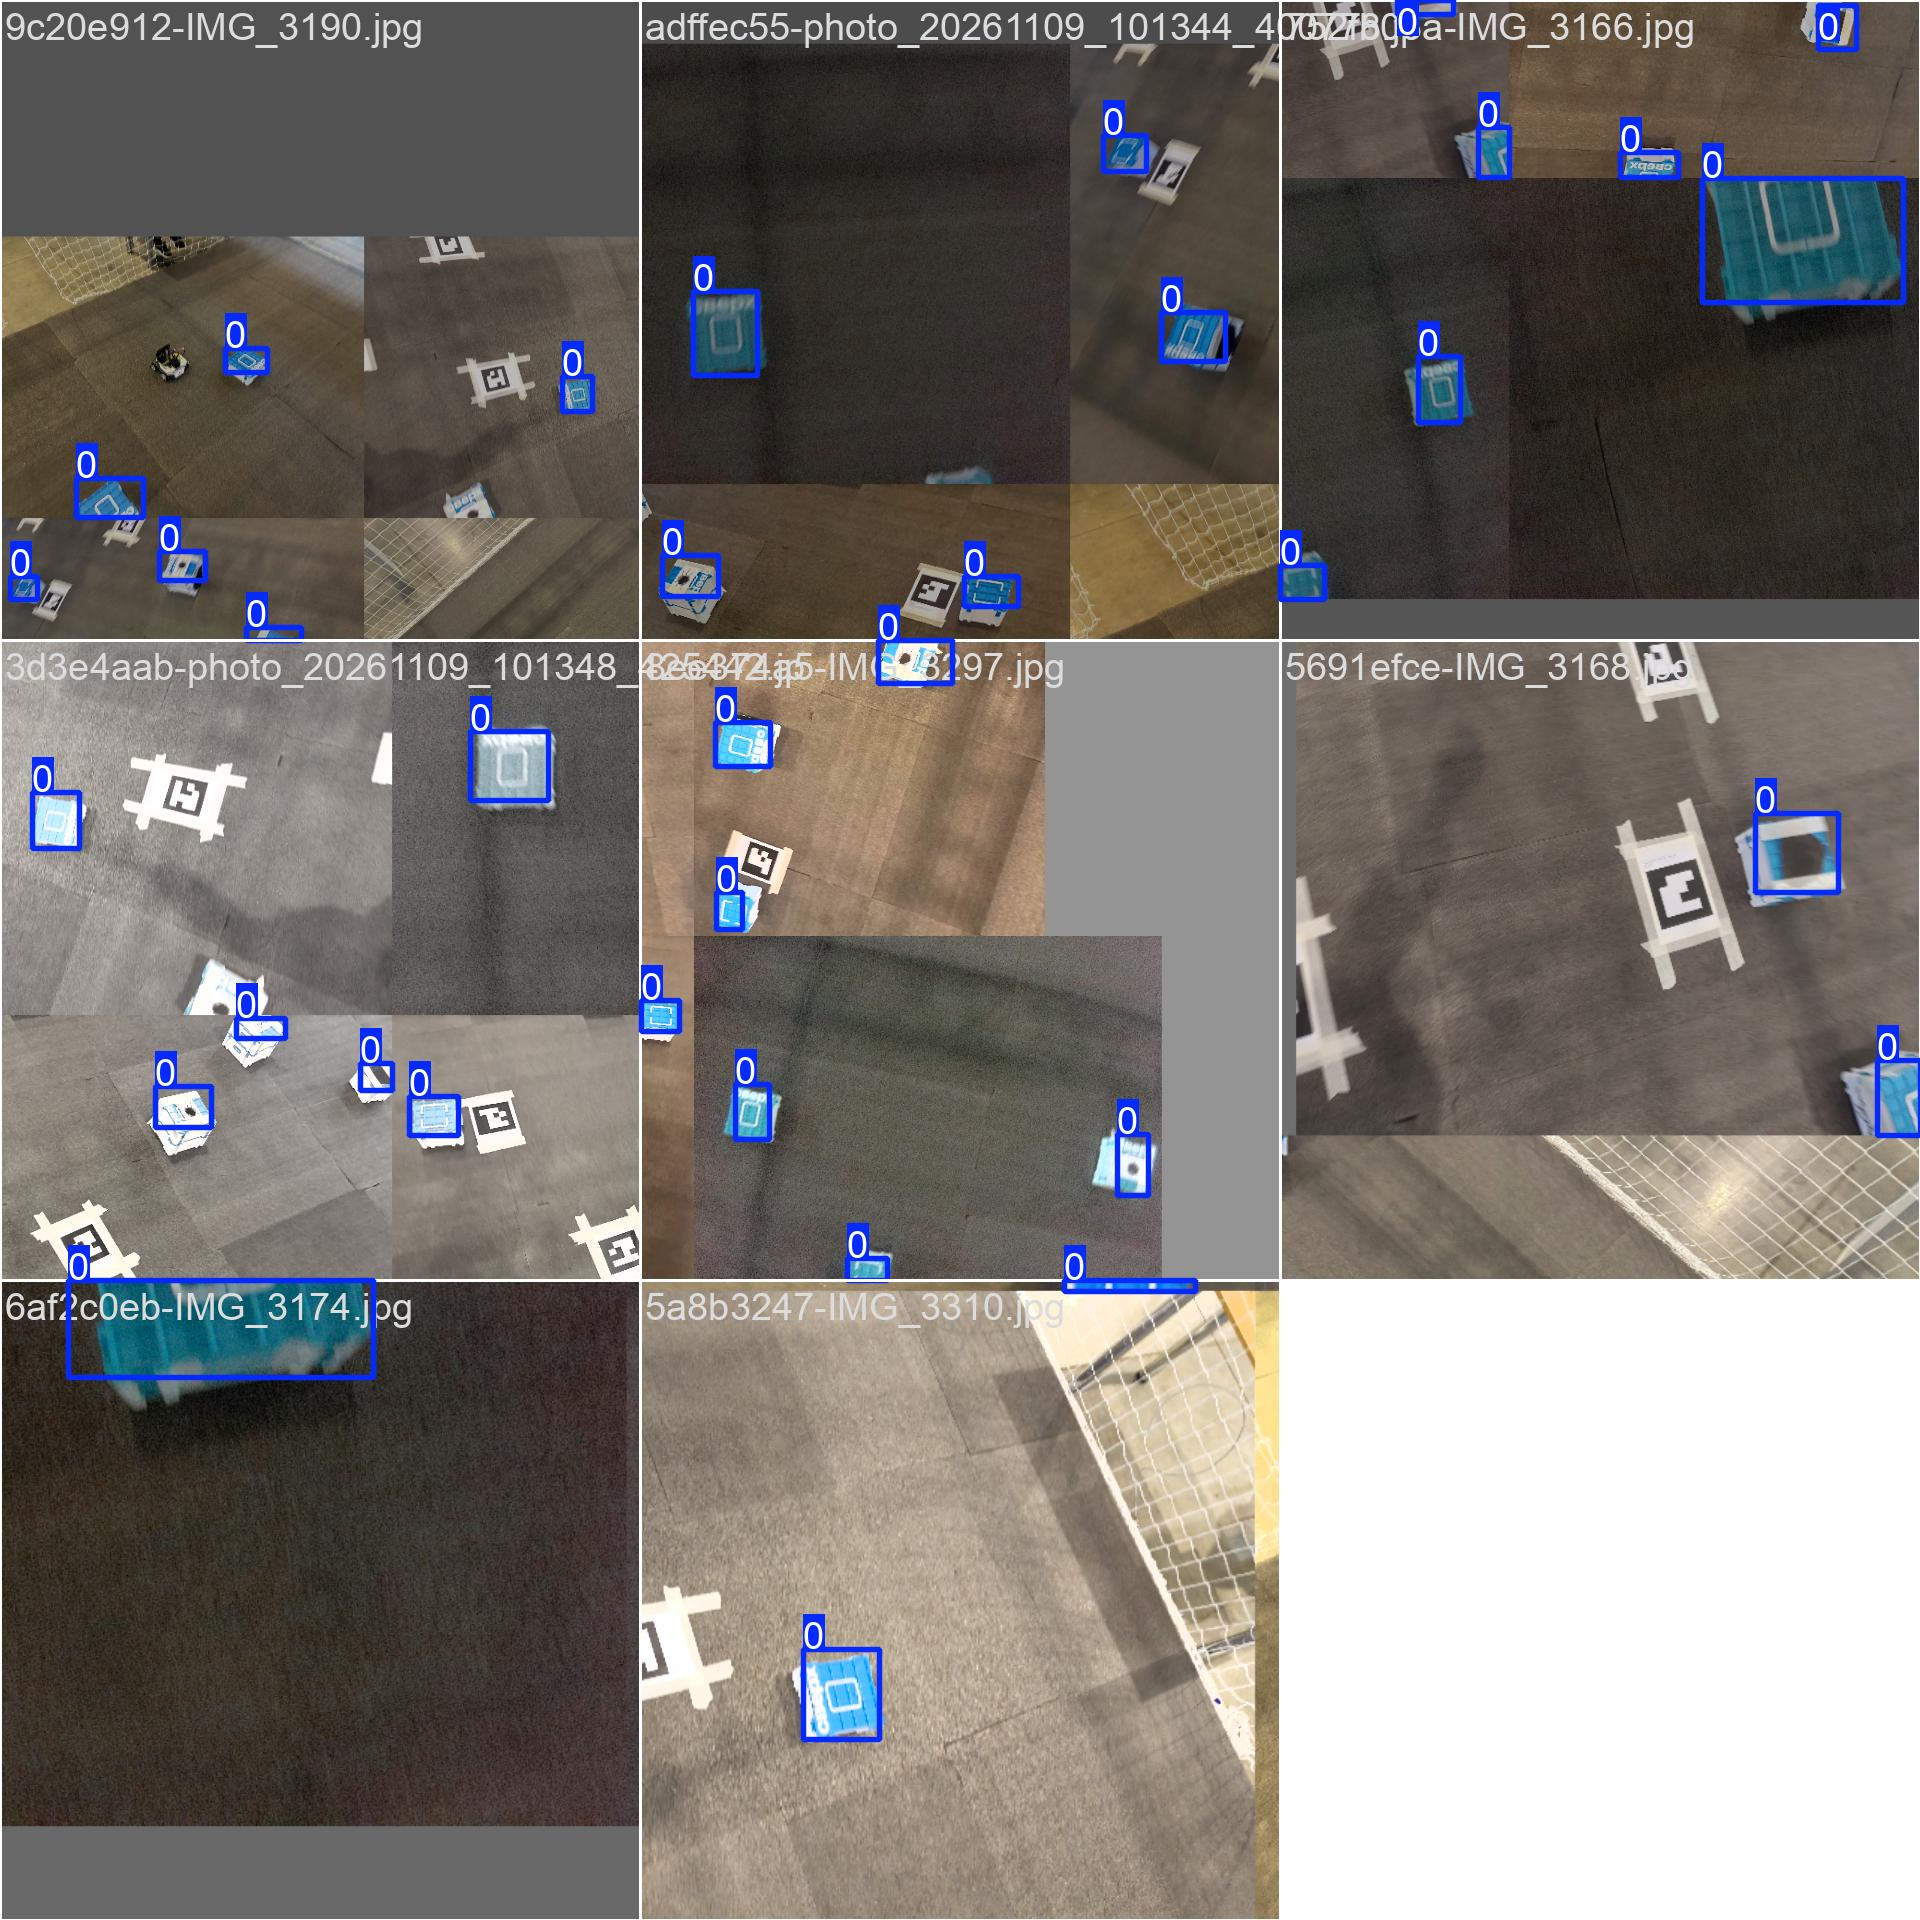

val_batch0_labels.jpg


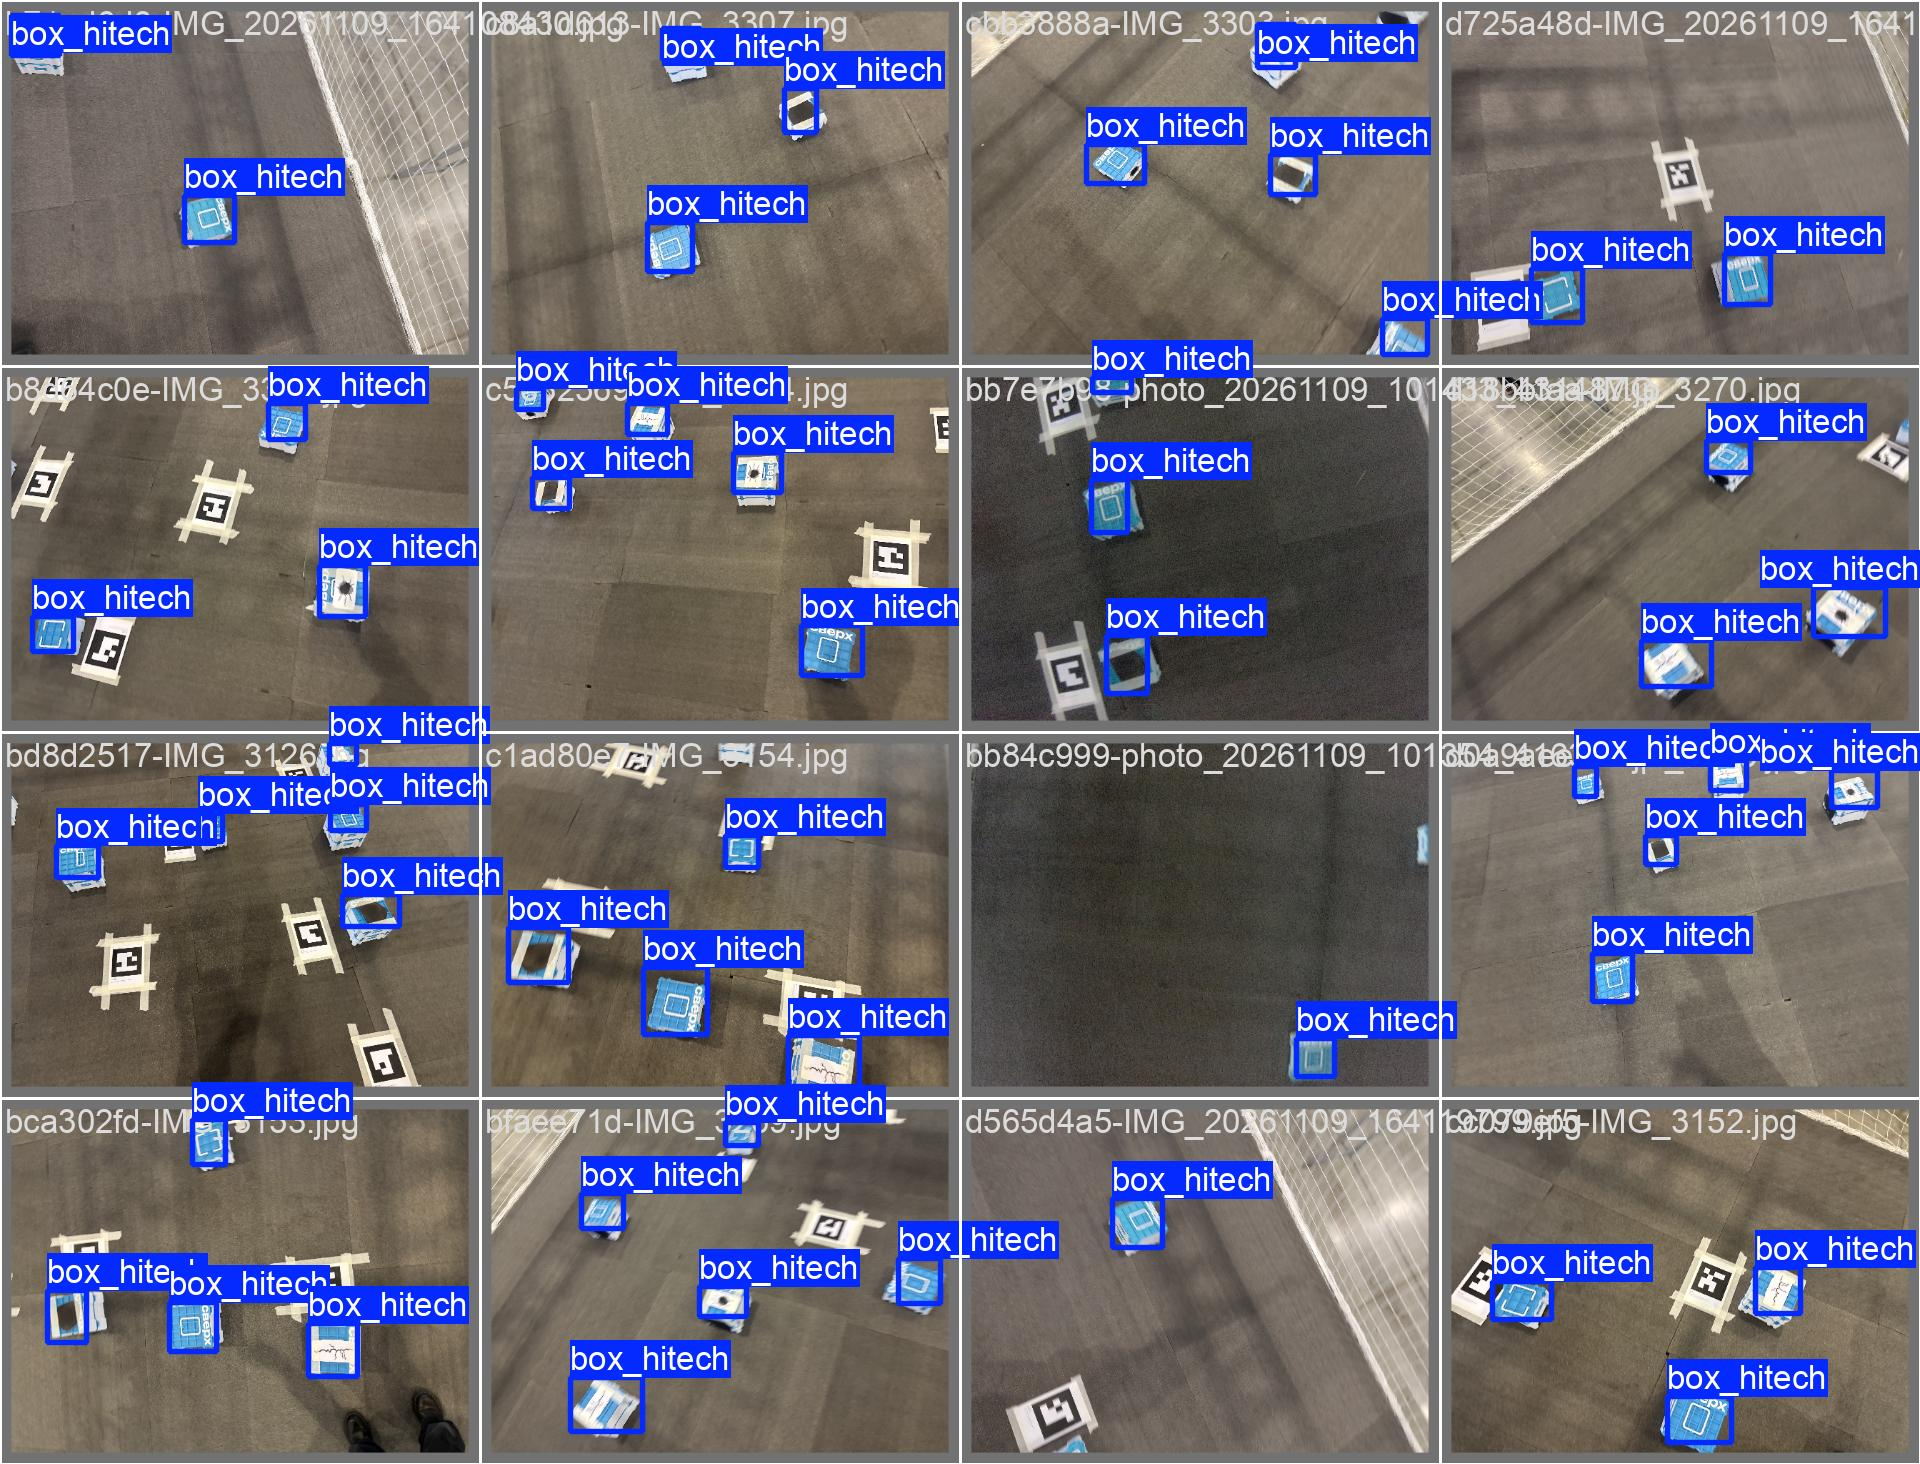

val_batch1_labels.jpg


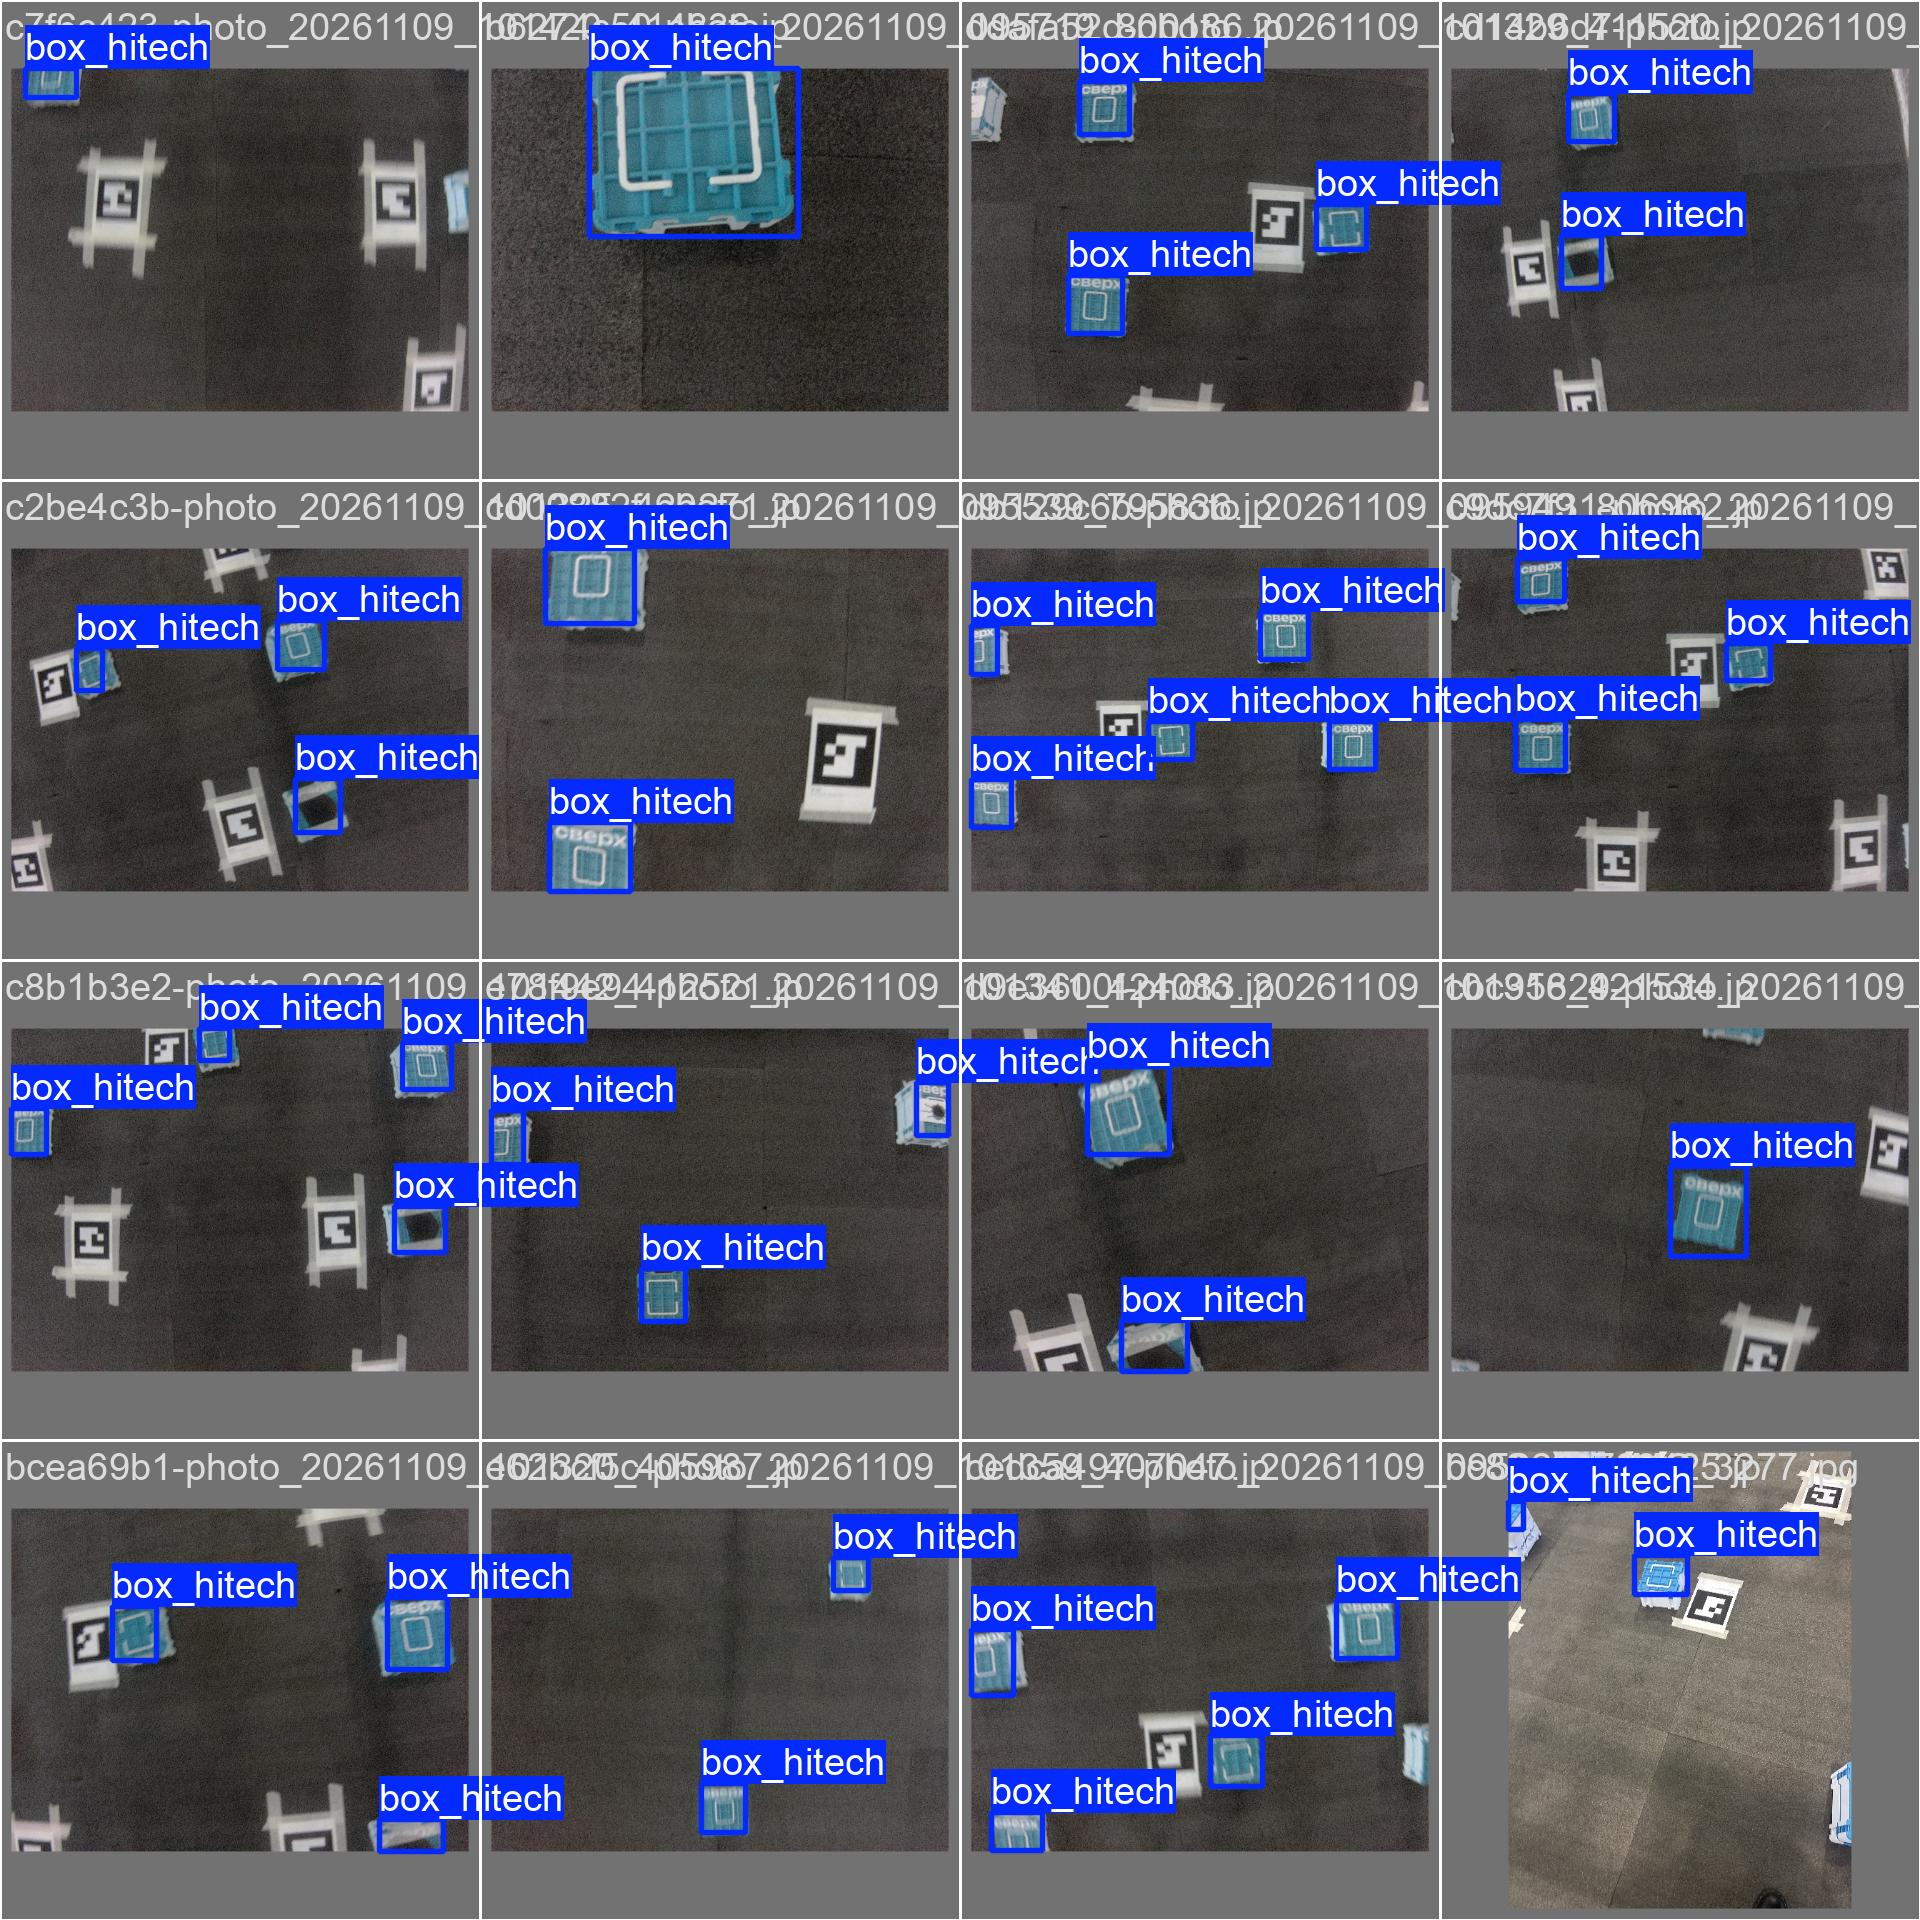

val_batch2_labels.jpg


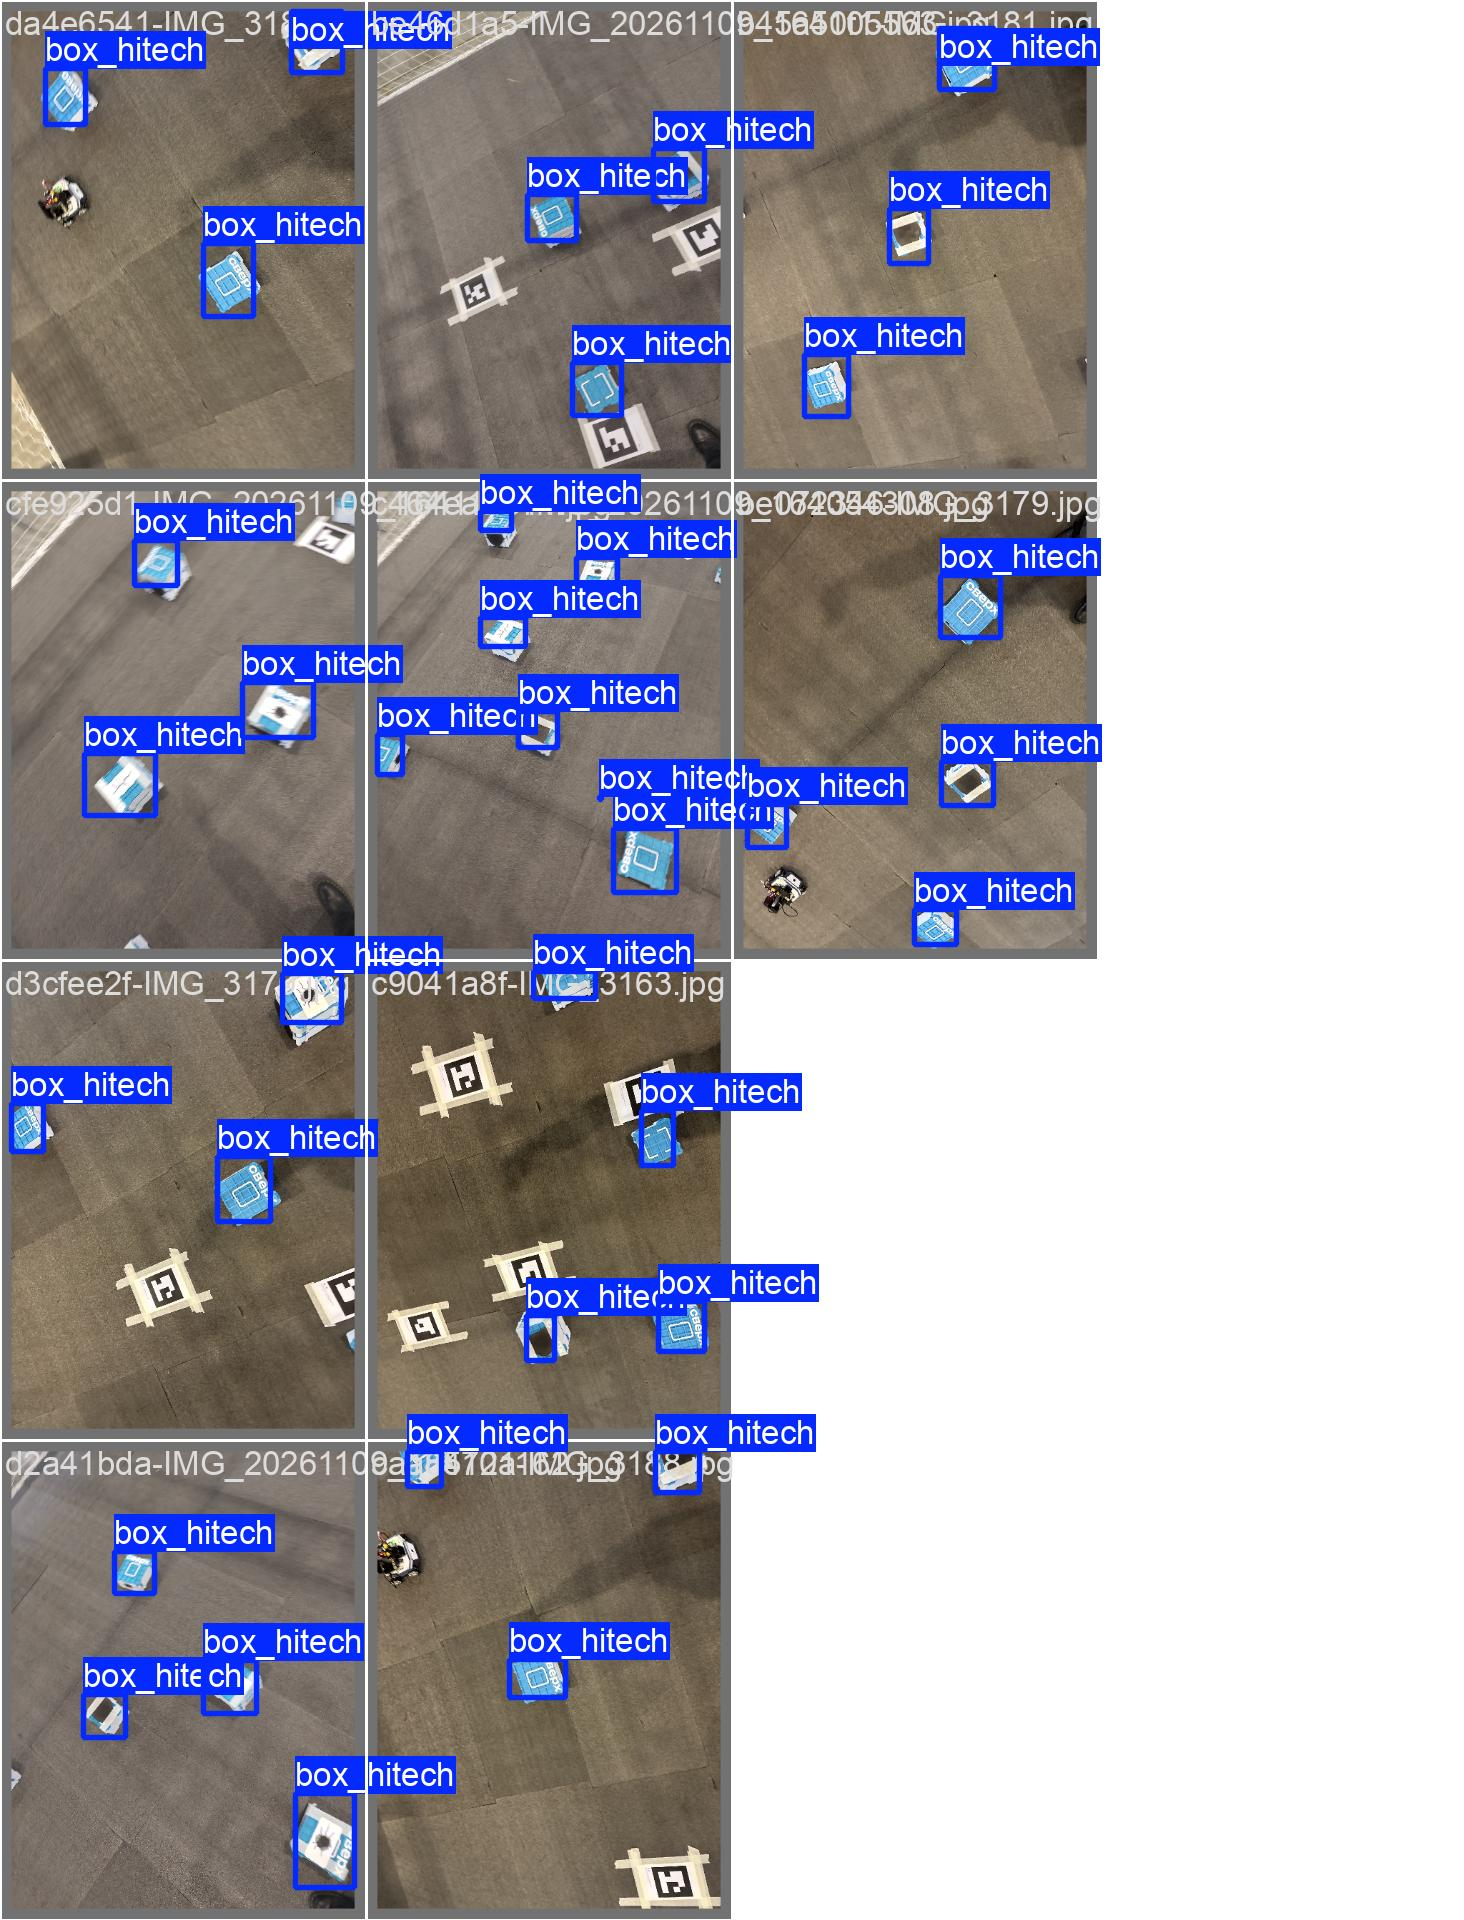

val_batch0_pred.jpg


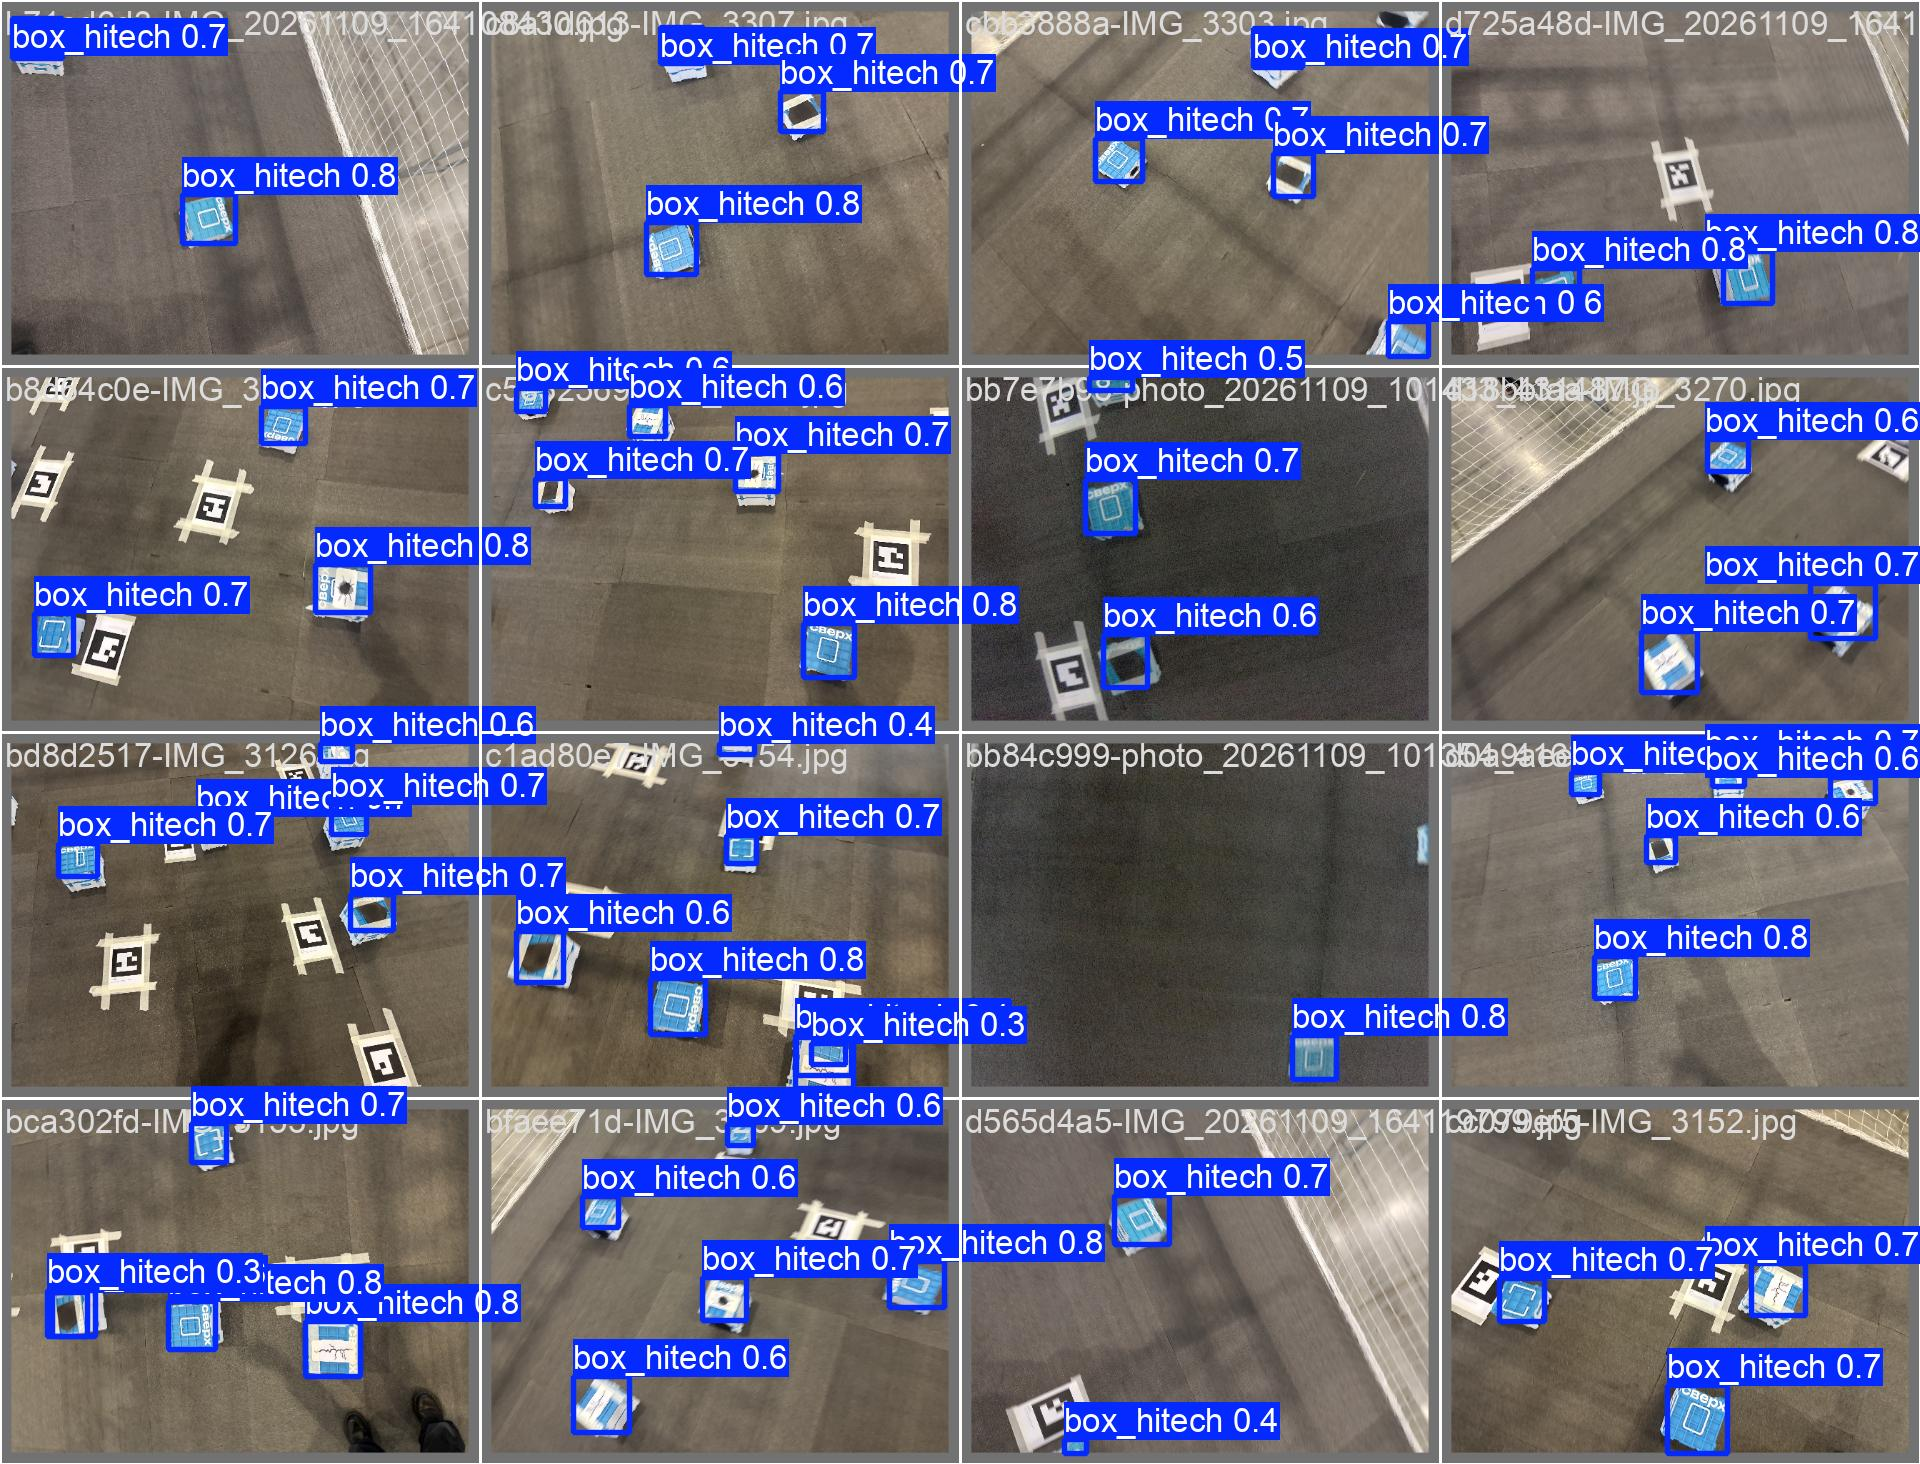

val_batch1_pred.jpg


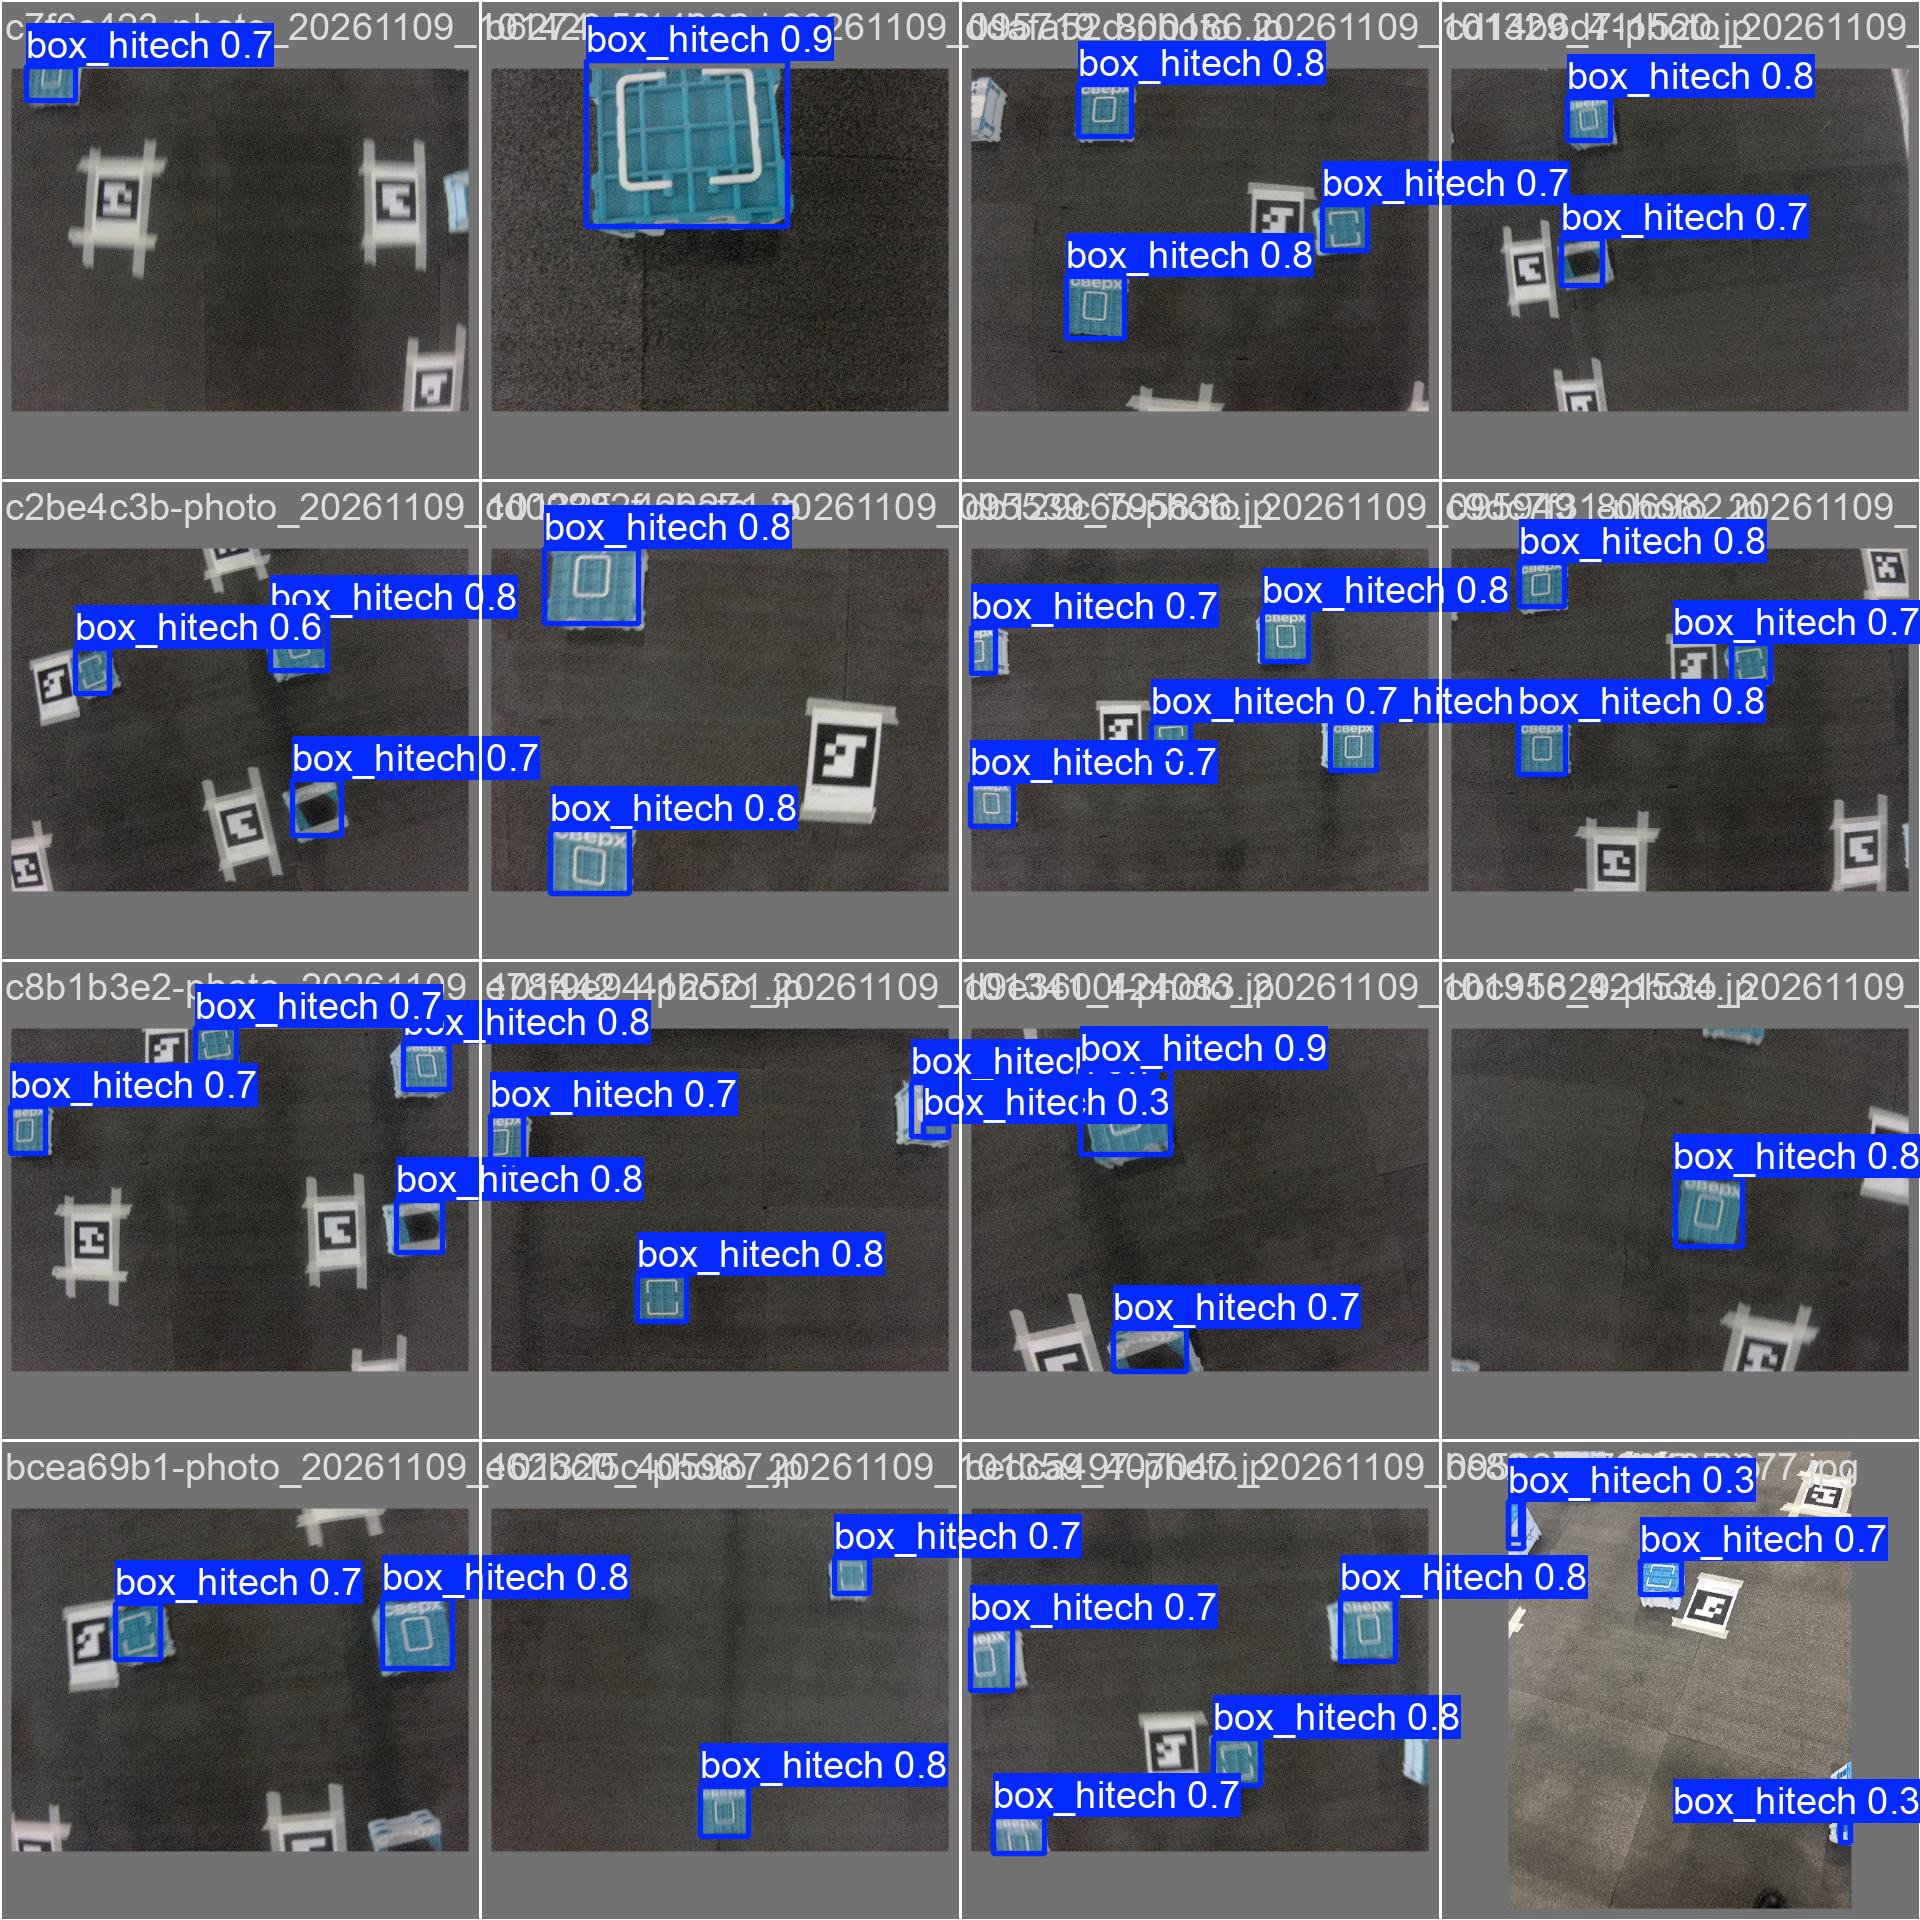

val_batch2_pred.jpg


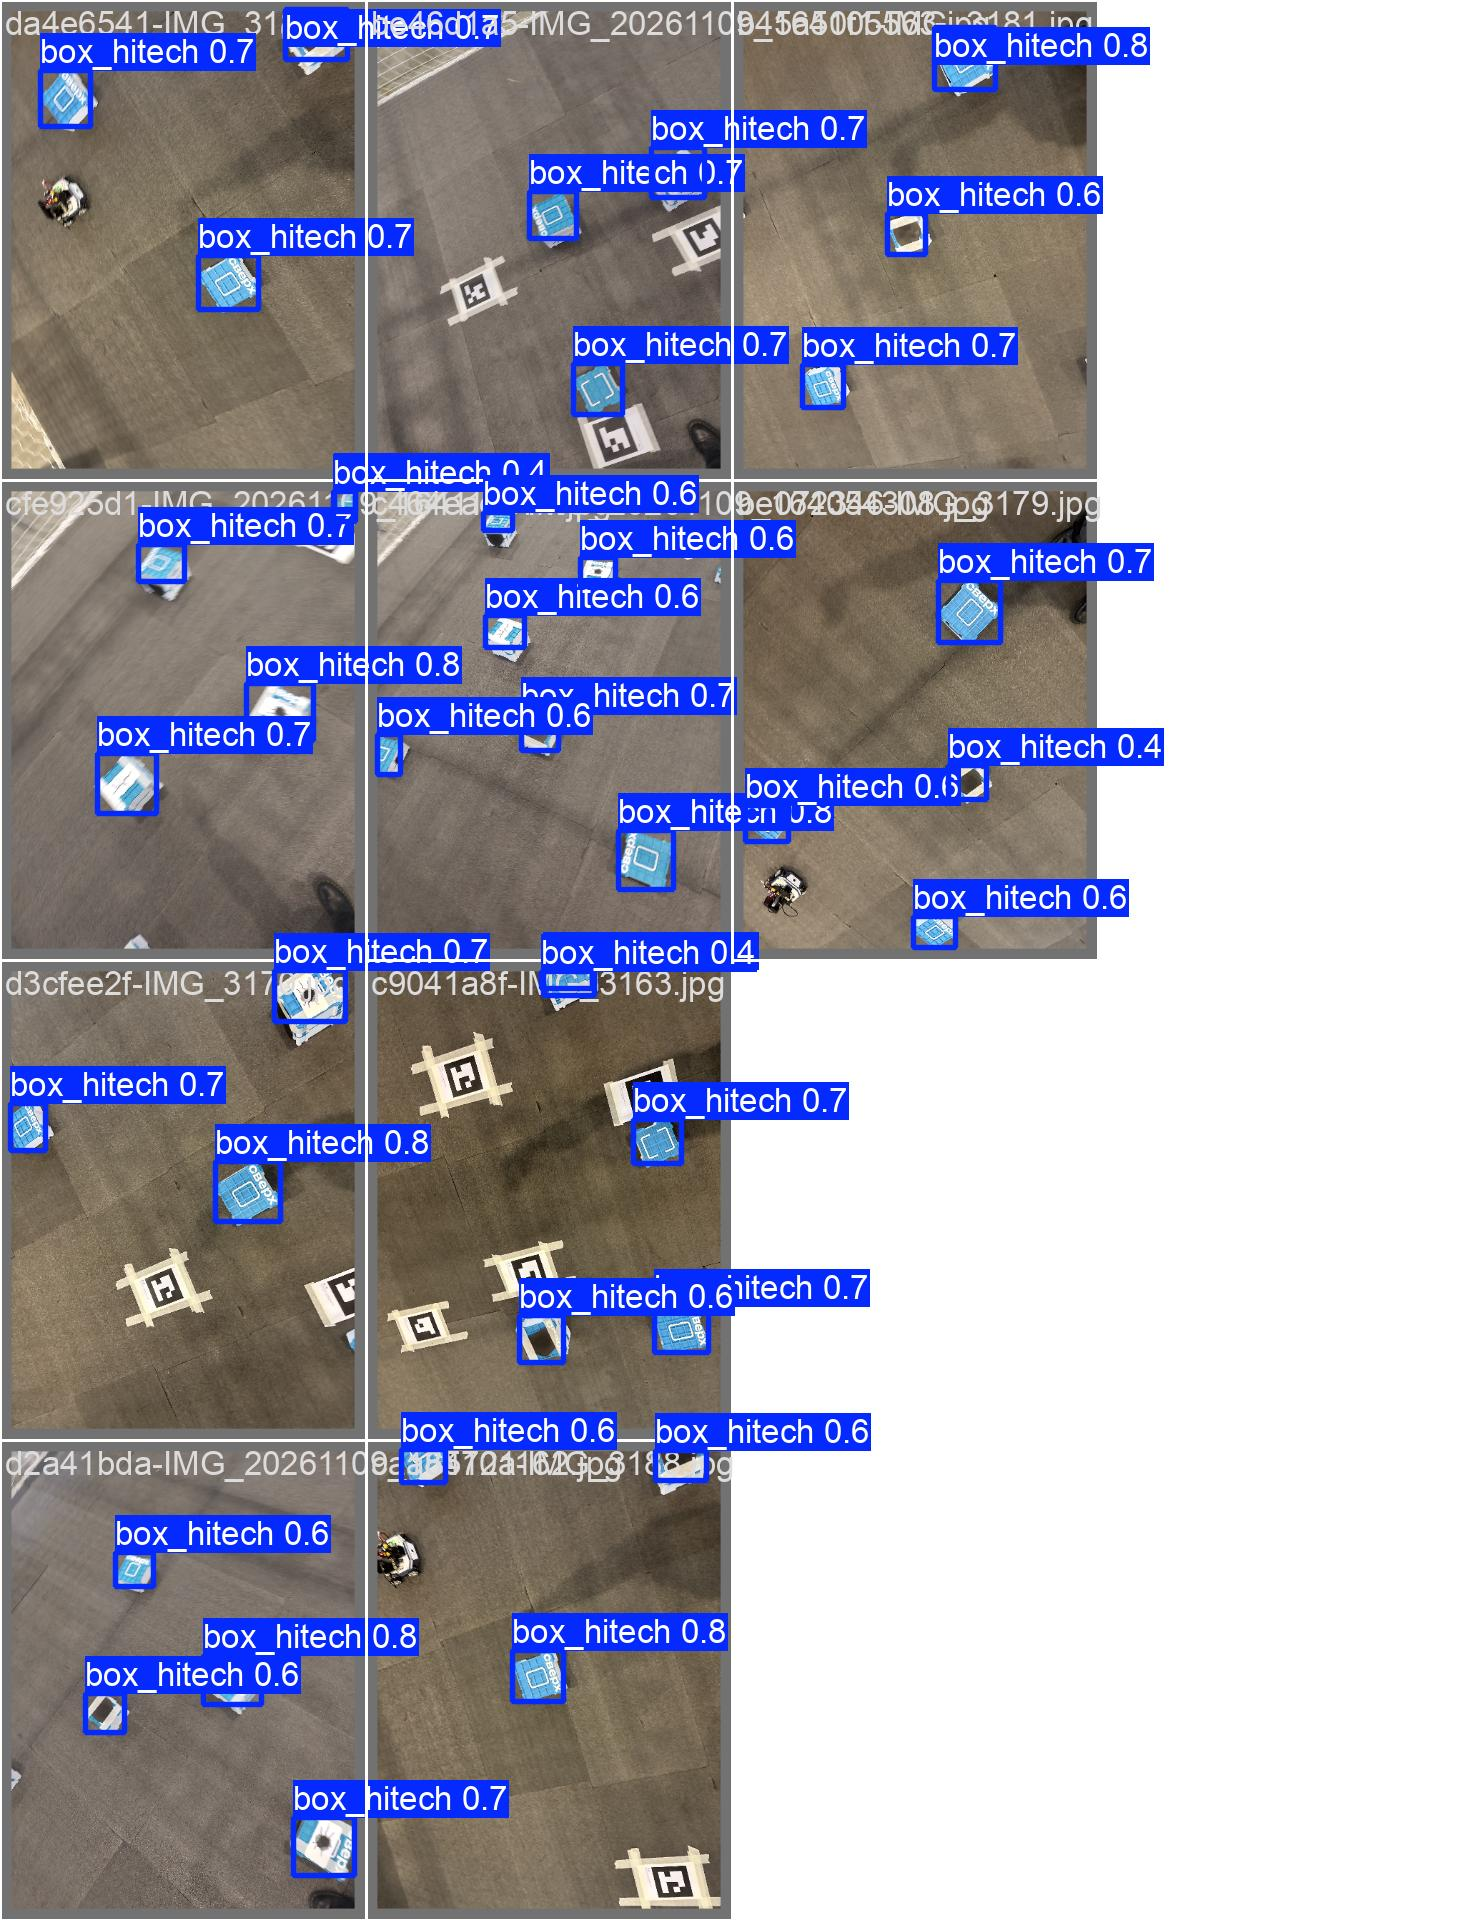

In [19]:
from pathlib import Path
from IPython.display import display, Image

run_dir = Path(
    "/content/drive/MyDrive/yolo_boxes/finetune_20261110_050439"
)


for filename in [
    "results.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
]:
    path = run_dir / filename
    if path.is_file():
        print(filename)
        display(Image(filename=str(path), width=900))


for pattern in [
    "train_batch*.jpg",
    "val_batch*_labels.jpg",
    "val_batch*_pred.jpg",
]:
    for path in sorted(run_dir.glob(pattern)):
        print(path.name)
        display(Image(filename=str(path), width=900))

In [ ]:
import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/yolo_all_results",
    "zip",
    root_dir=str(run_dir.parent),
    base_dir=run_dir.name,
)

files.download(archive)